# VentiMorph-RelNet | Journal analysis, part 2 

Probability-level OOF evaluation, calibration, qualitative predictions and explainability. The VRAA aggregation accepts DataFrames or lists and saves raw observations before bootstrapping.


In [1]:
from __future__ import annotations

import os
import re
import gc
import io
import json
import math
import random
import warnings
import hashlib
import zipfile
import shutil
from functools import lru_cache
from pathlib import Path
from typing import Literal

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from scipy import ndimage
from scipy.optimize import linear_sum_assignment

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
INFERENCE_BATCH_SIZE = 4
LOCKED_TEST_EVALUATION = False
EXPECTED_SPLIT_SHA256 = "d5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459"

OUTPUT_DIR = Path("/kaggle/working/ventimorph_v281_journal_analysis_step2")
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
QUAL_DIR = OUTPUT_DIR / "qualitative"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
QUAL_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
if DEVICE.type != "cuda":
    warnings.warn("A GPU is strongly recommended. Select a T4 GPU in Kaggle Settings.")

if LOCKED_TEST_EVALUATION:
    raise RuntimeError("Locked-test evaluation is intentionally disabled in the OOF validation notebook.")

print("STEP 2: frozen OOF probability/XAI inference only.")


Device: cuda
STEP 2: frozen OOF probability/XAI inference only.


In [2]:
def discover_ms3seg_root():
    required = {"MS_100_patient_preprocessed", "MS_100_patient_masks"}

    preferred = [
        Path("/kaggle/input/ms3seg/MS3SEG"),
        Path("/kaggle/input/ms3seg"),
        Path("/kaggle/input/datasets/saifsamiul/ms3seg/MS3SEG"),
    ]

    for candidate in preferred:
        if not candidate.exists() or not candidate.is_dir():
            continue
        names = {p.name for p in candidate.iterdir() if p.is_dir()}
        if required.issubset(names):
            return candidate

    input_root = Path("/kaggle/input")
    for preprocessed in input_root.rglob("MS_100_patient_preprocessed"):
        candidate = preprocessed.parent
        if (candidate / "MS_100_patient_masks").exists():
            return candidate

    raise FileNotFoundError("MS3SEG was not found. Attach the original MS3SEG Kaggle dataset.")


def discover_all_fold_bundles():
    input_root = Path("/kaggle/input")
    extraction_root = Path("/kaggle/working/v281_oof_checkpoint_extract")
    extraction_root.mkdir(parents=True, exist_ok=True)

    bundles = {}

    for fold in range(5):
        zip_candidates = [
            p for p in input_root.rglob("*.zip")
            if p.is_file()
            and p.name.startswith(f"MS3SEG_V281_FOLD{fold}_FULL60_TRANSFER")
        ]

        if zip_candidates:
            # Prefer the largest candidate in case browser-renamed duplicates exist.
            zip_path = sorted(zip_candidates, key=lambda p: p.stat().st_size, reverse=True)[0]
            fold_dir = extraction_root / f"fold{fold}"
            if fold_dir.exists():
                shutil.rmtree(fold_dir)
            fold_dir.mkdir(parents=True, exist_ok=True)

            with zipfile.ZipFile(zip_path, "r") as zf:
                zf.extractall(fold_dir)

            checkpoint = fold_dir / "best_model.pt"
            split_path = fold_dir / "patient_level_5fold_split.csv"
            metadata_path = fold_dir / "transfer_metadata.json"

            if not checkpoint.exists() or not split_path.exists():
                raise FileNotFoundError(
                    f"Fold {fold} transfer ZIP is missing best_model.pt or patient_level_5fold_split.csv: {zip_path}"
                )

            bundles[fold] = {
                "checkpoint": checkpoint,
                "split": split_path,
                "metadata": metadata_path if metadata_path.exists() else None,
                "source": zip_path,
            }
            continue

        # Also support already-extracted Kaggle checkpoint datasets.
        direct_candidates = []
        for p in input_root.rglob("best_model.pt"):
            meta = p.parent / "transfer_metadata.json"
            if not meta.exists():
                continue
            try:
                m = json.loads(meta.read_text(encoding="utf-8"))
            except Exception:
                continue

            meta_fold = m.get("fold", None)
            run_dir = str(m.get("run_directory", "")).lower()
            if meta_fold == fold or f"fold{fold}" in run_dir:
                split_path = p.parent / "patient_level_5fold_split.csv"
                if split_path.exists():
                    direct_candidates.append((p, split_path, meta))

        if not direct_candidates:
            raise FileNotFoundError(
                f"Fold {fold} checkpoint was not found. Attach a Kaggle input containing "
                f"MS3SEG_V281_FOLD{fold}_FULL60_TRANSFER.zip."
            )

        checkpoint, split_path, meta = direct_candidates[0]
        bundles[fold] = {
            "checkpoint": checkpoint,
            "split": split_path,
            "metadata": checkpoint.parent / "transfer_metadata.json",
            "source": checkpoint.parent,
        }

    return bundles


DATA_ROOT = discover_ms3seg_root()
CHECKPOINT_BUNDLES = discover_all_fold_bundles()

PREPROCESSED_DIR = DATA_ROOT / "MS_100_patient_preprocessed"
MASKS_DIR = DATA_ROOT / "MS_100_patient_masks"

print("Dataset root:", DATA_ROOT)
for fold, info in CHECKPOINT_BUNDLES.items():
    print(f"Fold {fold} checkpoint source:", info["source"])


Dataset root: /kaggle/input/datasets/saifsamiul/ms3seg/MS3SEG
Fold 0 checkpoint source: /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD0_FULL60_TRANSFER (1)
Fold 1 checkpoint source: /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD1_FULL60_TRANSFER
Fold 2 checkpoint source: /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD2_FULL60_TRANSFER
Fold 3 checkpoint source: /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD3_FULL60_TRANSFER
Fold 4 checkpoint source: /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD4_FULL60_TRANSFER


In [3]:
mask_roots = [
    path
    for path in MASKS_DIR.iterdir()
    if path.is_dir()
]


def select_mask_root(kind):
    if kind == "vent":
        matches = [
            path
            for path in mask_roots
            if "vent" in path.name.lower()
        ]

    elif kind == "nwmh":
        matches = [
            path
            for path in mask_roots
            if (
                "nwmh" in path.name.lower()
                or "normal" in path.name.lower()
            )
            and "abwmh" not in path.name.lower()
            and "abnormal" not in path.name.lower()
        ]

    else:
        matches = [
            path
            for path in mask_roots
            if (
                "abwmh" in path.name.lower()
                or "abnormal" in path.name.lower()
            )
        ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one {kind} mask root, found: {matches}"
        )

    return matches[0]


VENT_ROOT = select_mask_root("vent")
NWMH_ROOT = select_mask_root("nwmh")
ABWMH_ROOT = select_mask_root("abwmh")


def find_unique_file(
    folder,
    patterns,
    description,
):
    found = []

    for pattern in patterns:
        found.extend(
            folder.glob(pattern)
        )

    unique = []
    seen = set()

    for path in found:
        if (
            path.is_file()
            and path not in seen
        ):
            unique.append(path)
            seen.add(path)

    if len(unique) != 1:
        raise FileNotFoundError(
            f"{description}: expected one file in {folder}; "
            f"found {len(unique)}: {unique}"
        )

    return unique[0]


patient_dirs = sorted(
    path
    for path in PREPROCESSED_DIR.iterdir()
    if (
        path.is_dir()
        and re.fullmatch(
            r"\d{3}",
            path.name,
        )
    )
)

records = []

for patient_dir in patient_dirs:
    patient_id = patient_dir.name

    records.append({
        "patient_id": patient_id,
        "flair": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_FLAIR.nii",
                    f"{patient_id}_FLAIR.nii.gz",
                ],
                f"{patient_id} FLAIR",
            )
        ),
        "t1": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_T1WI_reg.nii",
                    f"{patient_id}_T1WI_reg.nii.gz",
                    "*T1*reg*.nii*",
                ],
                f"{patient_id} T1",
            )
        ),
        "t2": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_T2WI_reg.nii",
                    f"{patient_id}_T2WI_reg.nii.gz",
                    "*T2*reg*.nii*",
                ],
                f"{patient_id} T2",
            )
        ),
        "vent": str(
            find_unique_file(
                VENT_ROOT / patient_id,
                [
                    f"{patient_id}_Vent_Mask.nii",
                    f"{patient_id}_Vent_Mask.nii.gz",
                    "*Vent*Mask*.nii*",
                ],
                f"{patient_id} ventricle mask",
            )
        ),
        "nwmh": str(
            find_unique_file(
                NWMH_ROOT / patient_id,
                [
                    f"{patient_id}_nWMH_Mask.nii",
                    f"{patient_id}_nWMH_Mask.nii.gz",
                    "*nWMH*Mask*.nii*",
                ],
                f"{patient_id} normal-WMH mask",
            )
        ),
        "abwmh": str(
            find_unique_file(
                ABWMH_ROOT / patient_id,
                [
                    f"{patient_id}_abWMH_Mask.nii",
                    f"{patient_id}_abWMH_Mask.nii.gz",
                    "*abWMH*Mask*.nii*",
                ],
                f"{patient_id} abnormal-WMH mask",
            )
        ),
    })


manifest = (
    pd.DataFrame(records)
    .sort_values("patient_id")
    .reset_index(drop=True)
)

manifest["patient_id"] = (
    manifest["patient_id"]
    .astype(str)
    .str.zfill(3)
)

manifest_by_id = manifest.set_index("patient_id")

print("Patients found:", len(manifest))

if len(manifest) != 100:
    warnings.warn(
        f"Expected 100 patients but found {len(manifest)}."
    )

display(manifest.head())

Patients found: 100


,patient_id,flair,t1,t2,vent,nwmh,abwmh
0,001,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
1,002,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
2,003,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
3,004,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
4,005,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...


In [4]:
# Verify that every checkpoint bundle carries the exact same frozen split.
split_hashes = {}
split_frames = {}

for fold, info in CHECKPOINT_BUNDLES.items():
    raw = info["split"].read_bytes()
    sha = hashlib.sha256(raw).hexdigest()
    split_hashes[fold] = sha

    frame = pd.read_csv(info["split"], dtype={"patient_id": str})
    frame["patient_id"] = frame["patient_id"].astype(str).str.zfill(3)
    split_frames[fold] = frame

print("Split hashes:", split_hashes)

if len(set(split_hashes.values())) != 1:
    raise RuntimeError("The five checkpoint bundles do not contain identical patient splits.")

if next(iter(split_hashes.values())) != EXPECTED_SPLIT_SHA256:
    raise RuntimeError(
        "Frozen split checksum differs from the completed Fold-0 experiment. "
        "Do not evaluate until the correct checkpoint packages are attached."
    )

split_df = split_frames[0].copy()

required_columns = {"patient_id", "fold", "role"}
missing = required_columns - set(split_df.columns)
if missing:
    raise ValueError(f"Frozen split is missing columns: {sorted(missing)}")

locked_test_ids = sorted(
    split_df.loc[split_df["role"] == "test", "patient_id"].astype(str).str.zfill(3).unique()
)

if len(locked_test_ids) != 20:
    raise RuntimeError(f"Expected 20 locked-test patients, found {len(locked_test_ids)}.")

validation_ids_by_fold = {}

for fold in range(5):
    val_ids = sorted(
        split_df.loc[
            (split_df["fold"] == fold) & (split_df["role"] == "val"),
            "patient_id",
        ].astype(str).str.zfill(3).unique()
    )
    train_ids = sorted(
        split_df.loc[
            (split_df["fold"] == fold) & (split_df["role"] == "train"),
            "patient_id",
        ].astype(str).str.zfill(3).unique()
    )

    if len(train_ids) != 64 or len(val_ids) != 16:
        raise RuntimeError(
            f"Fold {fold} split is invalid: train={len(train_ids)}, val={len(val_ids)}."
        )
    if set(train_ids) & set(val_ids):
        raise RuntimeError(f"Fold {fold} train/validation overlap detected.")
    if set(val_ids) & set(locked_test_ids):
        raise RuntimeError(f"Fold {fold} validation/locked-test overlap detected.")

    validation_ids_by_fold[fold] = val_ids

all_oof_ids = [pid for fold in range(5) for pid in validation_ids_by_fold[fold]]

if len(all_oof_ids) != 80 or len(set(all_oof_ids)) != 80:
    raise RuntimeError("The 5-fold validation union must contain each of the 80 development patients exactly once.")

dataset_ids = set(manifest["patient_id"])
split_ids = set(split_df["patient_id"].astype(str).str.zfill(3))
if dataset_ids != split_ids:
    raise RuntimeError("MS3SEG patient IDs do not match the frozen checkpoint split.")

print("Frozen split verification: PASSED")
print("OOF development patients:", len(all_oof_ids))
print("Locked-test patients protected:", len(locked_test_ids))


Split hashes: {0: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 1: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 2: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 3: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 4: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459'}
Frozen split verification: PASSED
OOF development patients: 80
Locked-test patients protected: 20


In [5]:
@lru_cache(maxsize=8)
def load_volume(path):
    return np.asarray(
        nib.load(
            path,
            mmap=True,
        ).dataobj,
        dtype=np.float32,
    )


@lru_cache(maxsize=6)
def load_normalized_volume(path):
    array = load_volume(path).copy()

    finite = np.isfinite(array)
    nonzero = (
        finite
        & (
            np.abs(array)
            > 1e-6
        )
    )

    if nonzero.sum() < 100:
        return np.nan_to_num(
            array
        ).astype(np.float32)

    low, high = np.percentile(
        array[nonzero],
        [
            0.5,
            99.5,
        ],
    )

    high = max(
        high,
        low + 1.0,
    )

    array = np.clip(
        array,
        low,
        high,
    )

    array = (
        array
        - array[nonzero].mean()
    ) / (
        array[nonzero].std()
        + 1e-6
    )

    array[~finite] = 0.0

    return array.astype(
        np.float32
    )


@lru_cache(maxsize=48)
def load_binary_mask(path):
    return (
        load_volume(path)
        > 0
    ).astype(np.uint8)


def compose_target(row):
    ventricle = load_binary_mask(
        row.vent
    )

    normal_wmh = load_binary_mask(
        row.nwmh
    )

    abnormal_wmh = load_binary_mask(
        row.abwmh
    )

    target = np.zeros(
        ventricle.shape,
        dtype=np.uint8,
    )

    target[
        ventricle
        > 0
    ] = 1

    target[
        normal_wmh
        > 0
    ] = 2

    target[
        abnormal_wmh
        > 0
    ] = 3

    return target


def triplet(
    volume,
    slice_index,
):
    depth = volume.shape[2]

    indices = [
        max(
            0,
            slice_index - 1,
        ),
        slice_index,
        min(
            depth - 1,
            slice_index + 1,
        ),
    ]

    return np.stack(
        [
            volume[
                :,
                :,
                index,
            ]
            for index in indices
        ],
        axis=0,
    )


def build_patient_inputs(row):
    flair = load_normalized_volume(
        row.flair
    )

    t1 = load_normalized_volume(
        row.t1
    )

    t2 = load_normalized_volume(
        row.t2
    )

    depth = flair.shape[2]

    inputs = []

    for slice_index in range(depth):
        inputs.append(
            np.concatenate(
                [
                    triplet(
                        flair,
                        slice_index,
                    ),
                    triplet(
                        t1,
                        slice_index,
                    ),
                    triplet(
                        t2,
                        slice_index,
                    ),
                ],
                axis=0,
            )
        )

    return np.stack(
        inputs,
        axis=0,
    ).astype(np.float32)

In [6]:
class ConvNormAct(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, stride=1, groups=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, k, stride=stride, padding=k//2, groups=groups, bias=False),
            nn.GroupNorm(min(8, out_ch), out_ch),
            nn.SiLU(inplace=True),
        )
    def forward(self, x): return self.net(x)

class ResidualBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.c1 = ConvNormAct(ch, ch)
        self.c2 = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1, bias=False),
                                nn.GroupNorm(min(8, ch), ch))
        self.act = nn.SiLU(inplace=True)
    def forward(self, x): return self.act(x + self.c2(self.c1(x)))

class SE(nn.Module):
    def __init__(self, ch, r=8):
        super().__init__()
        h = max(8, ch // r)
        self.net = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(ch, h, 1),
                                 nn.SiLU(inplace=True), nn.Conv2d(h, ch, 1), nn.Sigmoid())
    def forward(self, x): return x * self.net(x)

class ModalityStem(nn.Module):
    def __init__(self, out_ch):
        super().__init__()
        self.net = nn.Sequential(ConvNormAct(3, out_ch), ResidualBlock(out_ch), SE(out_ch))
    def forward(self, x): return self.net(x)

def _safe_groups(channels, preferred=8):
    for g in (preferred, 4, 2, 1):
        if channels % g == 0:
            return g
    return 1

class ModalityGatedFusion(nn.Module):
    def __init__(self, ch):
        super().__init__()
        hidden = max(8, ch // 2)
        self.gate = nn.Sequential(
            nn.Conv2d(ch * 3, hidden, 1, bias=False),
            nn.GroupNorm(_safe_groups(hidden), hidden),
            nn.SiLU(inplace=True),
            nn.Conv2d(hidden, 3, 1),
        )
        self.refine = ResidualBlock(ch)
    def forward(self, f, t1, t2):
        # Per-pixel modality gate (was: one global-average-pooled scalar
        # weight per modality per sample). Lets FLAIR/T2 dominate locally
        # around WMH and T1 dominate near ventricle boundaries instead of
        # blending all three modalities with a single whole-image weight.
        stacked = torch.cat([f, t1, t2], 1)
        w = torch.softmax(self.gate(stacked), 1)
        fused = w[:, 0:1] * f + w[:, 1:2] * t1 + w[:, 2:3] * t2
        pooled_weights = w.mean(dim=(2, 3))
        return self.refine(fused), pooled_weights

class DownBlock(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.net = nn.Sequential(ConvNormAct(i, o, stride=2), ResidualBlock(o))
    def forward(self, x): return self.net(x)

class UpBlock(nn.Module):
    def __init__(self, i, s, o):
        super().__init__()
        self.net = nn.Sequential(ConvNormAct(i + s, o), ResidualBlock(o))
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.net(torch.cat([x, skip], 1))

class AdaptiveAnisotropicContext(nn.Module):
    def __init__(self, ch):
        super().__init__()
        b = ch // 4
        self.reduce = ConvNormAct(ch, b, 1)
        self.branches = nn.ModuleList([
            nn.Sequential(nn.Conv2d(b, b, 3, padding=d, dilation=d, groups=b, bias=False),
                          nn.GroupNorm(min(8, b), b), nn.SiLU(inplace=True))
            for d in (1, 2, 4, 6)
        ])
        self.mix = nn.Sequential(nn.Conv2d(b * 4, ch, 1, bias=False),
                                 nn.GroupNorm(min(8, ch), ch), nn.SiLU(inplace=True))
        self.se = SE(ch)
    def forward(self, x):
        r = self.reduce(x)
        y = self.se(self.mix(torch.cat([b(r) for b in self.branches], 1)))
        return x + y

class VentiMorphRefiner(nn.Module):
    def __init__(
        self,
        ch,
        mode: Literal["none", "vent", "distance", "directional"],
        max_residual: float = 0.25,
        stop_gradient_guidance: bool = True,
    ):
        super().__init__()
        self.mode = mode
        self.max_residual = float(max_residual)
        self.stop_gradient_guidance = bool(stop_gradient_guidance)
        self.vent_head = nn.Conv2d(ch, 1, 1)
        extras = {"none": 0, "vent": 1, "distance": 5, "directional": 9}[mode]
        self.orientation_head = nn.Conv2d(ch, 2, 1) if mode == "directional" else None
        self.refine = nn.Identity() if mode == "none" else nn.Sequential(
            ConvNormAct(ch + extras, ch), ResidualBlock(ch)
        )

        # Exact identity at initialization + hard amplitude cap.
        self.correction_gate = nn.Conv2d(ch, ch, 1) if mode != "none" else None
        if self.correction_gate is not None:
            nn.init.zeros_(self.correction_gate.weight)
            nn.init.zeros_(self.correction_gate.bias)

        sx = torch.tensor([[-1.,0.,1.],[-2.,0.,2.],[-1.,0.,1.]]).view(1,1,3,3)
        sy = torch.tensor([[-1.,-2.,-1.],[0.,0.,0.],[1.,2.,1.]]).view(1,1,3,3)
        self.register_buffer("sobel_x", sx)
        self.register_buffer("sobel_y", sy)

    def forward(self, feat):
        v_logit = self.vent_head(feat)
        v = torch.sigmoid(v_logit)
        relation = {"vent_logits": v_logit, "vent_prob": v}

        if self.mode == "none":
            return feat, relation

        # v2.8.1: segmentation refinement consumes the current anatomical
        # prediction but does not back-propagate its segmentation gradient
        # through the ventricle head. The ventricle head remains trainable
        # through the explicit auxiliary ventricle loss.
        guide_v = v.detach() if self.stop_gradient_guidance else v

        if self.mode == "vent":
            correction = self.correction_gate(
                self.refine(torch.cat([feat, guide_v], 1))
            )
            return feat + torch.tanh(correction) * self.max_residual, relation

        e1 = F.max_pool2d(guide_v, 7, 1, 3)
        e2 = F.max_pool2d(guide_v, 21, 1, 10)
        near = torch.clamp(e1 - guide_v, 0, 1)
        mid = torch.clamp(e2 - e1, 0, 1)
        far = torch.clamp(1 - e2, 0, 1)
        dist = 0.2 * near + 0.6 * mid + far
        relation.update({"near": near, "mid": mid, "far": far, "soft_distance": dist})
        extras = [guide_v, near, mid, far, dist]

        if self.mode == "directional":
            normal = torch.cat([
                F.conv2d(dist, self.sobel_x, padding=1),
                F.conv2d(dist, self.sobel_y, padding=1),
            ], 1)
            normal = F.normalize(normal, dim=1, eps=1e-6)
            orient = F.normalize(self.orientation_head(feat), dim=1, eps=1e-6)
            radial = torch.abs((normal * orient).sum(1, keepdim=True))
            tangential = 1 - radial
            relation.update({
                "normal_x": normal[:,0:1], "normal_y": normal[:,1:2],
                "orientation_x": orient[:,0:1], "orientation_y": orient[:,1:2],
                "radial": radial, "tangential": tangential,
            })
            extras += [normal[:,0:1], normal[:,1:2], radial, tangential]

        correction = self.correction_gate(
            self.refine(torch.cat([feat] + extras, 1))
        )
        return feat + torch.tanh(correction) * self.max_residual, relation


class RelationConditionedPrototypeBank(nn.Module):
    # Retained only for later ablation work; disabled in the v2.8.1 primary run.
    def __init__(self, dim=32, temperature=0.1):
        super().__init__()
        self.temperature = temperature
        self.prototypes = nn.Parameter(F.normalize(torch.randn(2, 3, dim), dim=-1))

    def loss(self, embedding, target, region, max_samples=4096):
        feat = embedding.permute(0, 2, 3, 1)
        idx = ((target == 2) | (target == 3)).nonzero(as_tuple=False)
        if idx.numel() == 0:
            return embedding.sum() * 0
        if idx.shape[0] > max_samples:
            idx = idx[torch.randperm(idx.shape[0], device=idx.device)[:max_samples]]
        b, y, x = idx[:,0], idx[:,1], idx[:,2]
        f = F.normalize(feat[b, y, x], dim=1)
        label = (target[b, y, x] == 3).long()
        r = region[b, y, x].clamp(0, 2).long()
        p = F.normalize(self.prototypes, dim=-1)[:, r, :].permute(1, 0, 2)
        logits = torch.einsum("nd,ncd->nc", f, p) / self.temperature
        return F.cross_entropy(logits, label)


class VentiMorphRelNet(nn.Module):
    def __init__(
        self,
        base=24,
        num_classes=4,
        use_multimodal=True,
        use_context=True,
        guidance_mode="directional",
        mid_guidance_mode="vent",
        use_prototypes=False,
        use_uncertainty=False,
        deep_supervision=True,
        emb_dim=32,
        mid_relation_residual=0.15,
        final_relation_residual=0.25,
    ):
        super().__init__()
        self.use_multimodal = use_multimodal
        self.use_prototypes = use_prototypes
        self.use_uncertainty = use_uncertainty
        self.deep_supervision = deep_supervision

        self.flair_stem, self.t1_stem, self.t2_stem = [ModalityStem(base) for _ in range(3)]
        self.fusion = ModalityGatedFusion(base)

        self.e0 = nn.Sequential(ConvNormAct(base, 32), ResidualBlock(32))
        self.e1, self.e2, self.e3, self.e4 = (
            DownBlock(32,64), DownBlock(64,128), DownBlock(128,192), DownBlock(192,256)
        )
        self.context = AdaptiveAnisotropicContext(256) if use_context else ResidualBlock(256)
        self.drop = nn.Dropout2d(0.1)
        self.d3, self.d2, self.d1, self.d0 = (
            UpBlock(256,192,192), UpBlock(192,128,128),
            UpBlock(128,64,64), UpBlock(64,32,32)
        )

        # v2.8.1: coarse decoder gets only robust ventricle guidance.
        # Distance/directional morphology is injected only at full resolution.
        self.mid_guide = VentiMorphRefiner(
            128, mid_guidance_mode,
            max_residual=mid_relation_residual,
            stop_gradient_guidance=True,
        )
        self.final_guide = VentiMorphRefiner(
            32, guidance_mode,
            max_residual=final_relation_residual,
            stop_gradient_guidance=True,
        )

        # Prototype/evidential branches are optional research ablations, not
        # part of the primary segmentation-first v2.8.1 training objective.
        self.embedding = (
            nn.Sequential(ConvNormAct(32, emb_dim), nn.Conv2d(emb_dim, emb_dim, 1))
            if use_prototypes else None
        )
        self.prototype_bank = (
            RelationConditionedPrototypeBank(emb_dim) if use_prototypes else None
        )
        self.evidence_head = nn.Conv2d(32, num_classes, 1) if use_uncertainty else None

        self.seg_head = nn.Conv2d(32, num_classes, 1)

        if self.deep_supervision:
            self.aux_head_d2 = nn.Conv2d(128, num_classes, 1)
            self.aux_head_d1 = nn.Conv2d(64, num_classes, 1)

    def forward(self, x):
        if x.ndim != 4 or x.shape[1] != 9:
            raise ValueError(f"Expected [B,9,H,W], got {tuple(x.shape)}")

        f = self.flair_stem(x[:,0:3])
        t1 = self.t1_stem(x[:,3:6]) if self.use_multimodal else torch.zeros_like(f)
        t2 = self.t2_stem(x[:,6:9]) if self.use_multimodal else torch.zeros_like(f)
        fused, weights = self.fusion(f, t1, t2)

        e0 = self.e0(fused)
        e1 = self.e1(e0)
        e2 = self.e2(e1)
        e3 = self.e3(e2)
        e4 = self.drop(self.context(self.e4(e3)))

        d3 = self.d3(e4, e3)
        d2, mid_rel = self.mid_guide(self.d2(d3, e2))
        d1 = self.d1(d2, e1)
        d0, final_rel = self.final_guide(self.d0(d1, e0))

        logits = self.seg_head(d0)
        emb = self.embedding(d0) if self.embedding is not None else None

        evidence = F.softplus(self.evidence_head(d0)) if self.evidence_head is not None else None
        alpha = evidence + 1 if evidence is not None else None
        uncertainty = 4.0 / alpha.sum(1, keepdim=True) if alpha is not None else None

        aux_logits_d2 = self.aux_head_d2(d2) if self.deep_supervision else None
        aux_logits_d1 = self.aux_head_d1(d1) if self.deep_supervision else None

        return {
            "segmentation_logits": logits,
            "embedding": emb,
            "modality_weights": weights,
            "mid_relation": mid_rel,
            "final_relation": final_rel,
            "evidence": evidence,
            "alpha": alpha,
            "uncertainty": uncertainty,
            "aux_logits_d2": aux_logits_d2,
            "aux_logits_d1": aux_logits_d1,
        }

    def prototype_loss(self, out, target, region):
        if self.prototype_bank is None or out["embedding"] is None:
            return out["segmentation_logits"].sum() * 0.0
        return self.prototype_bank.loss(out["embedding"], target, region)


In [7]:
def build_model_from_checkpoint(checkpoint_path, expected_fold):
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    if "model_state" not in checkpoint:
        raise KeyError(f"{checkpoint_path} does not contain model_state.")

    config = checkpoint.get("config", {})
    if int(config.get("fold", expected_fold)) != expected_fold:
        raise RuntimeError(
            f"Checkpoint/config fold mismatch: expected {expected_fold}, "
            f"found {config.get('fold')}."
        )

    model = VentiMorphRelNet(
        base=int(config.get("base", 24)),
        use_multimodal=bool(config.get("use_multimodal", True)),
        use_context=bool(config.get("use_context", True)),
        guidance_mode=str(config.get("guidance_mode", "directional")),
        mid_guidance_mode=str(config.get("mid_guidance_mode", "vent")),
        use_prototypes=bool(config.get("use_prototypes", False)),
        use_uncertainty=bool(config.get("use_uncertainty", False)),
        deep_supervision=bool(config.get("deep_supervision", True)),
        mid_relation_residual=float(config.get("mid_relation_residual", 0.15)),
        final_relation_residual=float(config.get("final_relation_residual", 0.25)),
    ).to(DEVICE)

    incompatible = model.load_state_dict(checkpoint["model_state"], strict=True)

    nonfinite = [
        name for name, tensor in checkpoint["model_state"].items()
        if torch.is_tensor(tensor) and not torch.isfinite(tensor).all()
    ]
    if nonfinite:
        raise RuntimeError(f"Fold {expected_fold} checkpoint contains non-finite tensors: {nonfinite[:10]}")

    model.eval()
    for parameter in model.parameters():
        parameter.requires_grad_(False)

    return model, checkpoint, config, incompatible




In [8]:
# Load OOF patient metrics for case selection.
def locate_oof_patient_metrics():
    direct = list(Path("/kaggle/input").rglob("v281_5fold_oof_patient_metrics.csv"))
    if direct:
        return direct[0]

    result_zips = [
        p for p in Path("/kaggle/input").rglob("*.zip")
        if p.name.startswith("MS3SEG_V281_5FOLD_OOF_VALIDATION_RESULTS")
    ]

    for zpath in result_zips:
        with zipfile.ZipFile(zpath, "r") as zf:
            matches = [
                n for n in zf.namelist()
                if Path(n).name == "v281_5fold_oof_patient_metrics.csv"
            ]
            if matches:
                target = OUTPUT_DIR / "v281_5fold_oof_patient_metrics_source.csv"
                target.write_bytes(zf.read(matches[0]))
                return target

    raise FileNotFoundError(
        "Could not find v281_5fold_oof_patient_metrics.csv. "
        "Attach the completed OOF validation-results Kaggle dataset."
    )


OOF_PATIENT_METRICS_PATH = locate_oof_patient_metrics()
oof_patient_df = pd.read_csv(
    OOF_PATIENT_METRICS_PATH,
    dtype={"patient_id": str},
)
oof_patient_df["patient_id"] = (
    oof_patient_df["patient_id"].astype(str).str.zfill(3)
)

if len(oof_patient_df) != 80 or oof_patient_df["patient_id"].nunique() != 80:
    raise RuntimeError(
        "Expected the completed 80-patient OOF patient-metrics table."
    )

if set(oof_patient_df["patient_id"]) & set(locked_test_ids):
    raise RuntimeError(
        "OOF metrics contain a locked-test patient. Stop immediately."
    )

print("OOF patient-metrics source:", OOF_PATIENT_METRICS_PATH)
print("OOF patients available:", oof_patient_df["patient_id"].nunique())


OOF patient-metrics source: /kaggle/input/datasets/sabatasnim123/ventimorph-5fold-oof-validation-results/v281_5fold_oof_patient_metrics.csv
OOF patients available: 80


In [9]:
# Streaming probability analysis
# We avoid storing billions of voxel probabilities. Instead, each class gets a
# high-resolution probability histogram for positive and negative voxels.
# This supports reproducible approximate PR/ROC curves with 4096 thresholds.

PROBABILITY_BINS = 4096
CALIBRATION_BINS = 20

CLASS_NAMES = {
    1: "Ventricle",
    2: "Normal-WMH",
    3: "Abnormal-WMH",
}

positive_hist = {
    class_id: np.zeros(PROBABILITY_BINS, dtype=np.int64)
    for class_id in CLASS_NAMES
}
negative_hist = {
    class_id: np.zeros(PROBABILITY_BINS, dtype=np.int64)
    for class_id in CLASS_NAMES
}

calibration_count = np.zeros(CALIBRATION_BINS, dtype=np.int64)
calibration_confidence_sum = np.zeros(CALIBRATION_BINS, dtype=np.float64)
calibration_correct_sum = np.zeros(CALIBRATION_BINS, dtype=np.float64)

total_voxels = 0
brier_sum = 0.0

per_fold_probability_rows = []


def update_probability_histogram(probability, truth_binary, class_id):
    indices = np.minimum(
        (probability * PROBABILITY_BINS).astype(np.int64),
        PROBABILITY_BINS - 1,
    )
    positive_hist[class_id] += np.bincount(
        indices[truth_binary],
        minlength=PROBABILITY_BINS,
    )
    negative_hist[class_id] += np.bincount(
        indices[~truth_binary],
        minlength=PROBABILITY_BINS,
    )


def update_calibration(probabilities, target):
    global total_voxels, brier_sum

    # probabilities: [4, H, W, Z], target: [H, W, Z]
    confidence = probabilities.max(axis=0)
    prediction = probabilities.argmax(axis=0)
    correct = (prediction == target).astype(np.float64)

    indices = np.minimum(
        (confidence * CALIBRATION_BINS).astype(np.int64),
        CALIBRATION_BINS - 1,
    )

    flat_idx = indices.ravel()
    flat_conf = confidence.ravel().astype(np.float64)
    flat_correct = correct.ravel()

    calibration_count[:] += np.bincount(
        flat_idx,
        minlength=CALIBRATION_BINS,
    )
    calibration_confidence_sum[:] += np.bincount(
        flat_idx,
        weights=flat_conf,
        minlength=CALIBRATION_BINS,
    )
    calibration_correct_sum[:] += np.bincount(
        flat_idx,
        weights=flat_correct,
        minlength=CALIBRATION_BINS,
    )

    one_hot = np.eye(4, dtype=np.float32)[target.ravel()]
    probs_flat = np.moveaxis(probabilities, 0, -1).reshape(-1, 4)

    brier_sum += float(
        np.square(probs_flat - one_hot).sum(axis=1).sum()
    )
    total_voxels += int(target.size)


@torch.inference_mode()
def infer_patient_probabilities(model, patient_id):
    patient_id = str(patient_id).zfill(3)
    row = manifest_by_id.loc[patient_id]

    inputs = build_patient_inputs(row)
    target = compose_target(row)

    probability_batches = []

    for start in range(0, len(inputs), INFERENCE_BATCH_SIZE):
        batch_np = inputs[start:start + INFERENCE_BATCH_SIZE]
        batch = torch.from_numpy(batch_np).to(DEVICE)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda"),
        ):
            output = model(batch)
            probability = torch.softmax(
                output["segmentation_logits"].float(),
                dim=1,
            )

        probability_batches.append(
            probability.cpu().numpy().astype(np.float32)
        )

        del batch, output, probability

    # [slice, class, x, y] -> [class, x, y, slice]
    probabilities = np.transpose(
        np.concatenate(probability_batches, axis=0),
        (1, 2, 3, 0),
    )

    if probabilities.shape[1:] != target.shape:
        raise RuntimeError(
            f"Probability/target shape mismatch for patient {patient_id}: "
            f"{probabilities.shape[1:]} vs {target.shape}"
        )

    return probabilities, target


for fold in range(5):
    print("\n" + "=" * 72)
    print(f"Probability analysis — Fold {fold}")
    print("=" * 72)

    model, checkpoint, config, incompatible = build_model_from_checkpoint(
        CHECKPOINT_BUNDLES[fold]["checkpoint"],
        expected_fold=fold,
    )

    fold_voxels = 0

    for number, patient_id in enumerate(
        validation_ids_by_fold[fold],
        start=1,
    ):
        probabilities, target = infer_patient_probabilities(
            model,
            patient_id,
        )

        for class_id in CLASS_NAMES:
            update_probability_histogram(
                probabilities[class_id],
                target == class_id,
                class_id,
            )

        update_calibration(
            probabilities,
            target,
        )

        fold_voxels += int(target.size)

        print(
            f"Fold {fold} [{number:02d}/16] "
            f"patient {patient_id} processed"
        )

        del probabilities, target
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    per_fold_probability_rows.append({
        "fold": fold,
        "patients": 16,
        "voxels": fold_voxels,
        "checkpoint_best_epoch": checkpoint.get("best_epoch"),
    })

    del model, checkpoint
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

probability_audit_df = pd.DataFrame(per_fold_probability_rows)
probability_audit_df.to_csv(
    TABLE_DIR / "step2_probability_inference_audit.csv",
    index=False,
)

print("\nProbability inference complete.")
print("OOF patients processed: 80")
print("Locked-test patients processed: 0")
display(probability_audit_df)



Probability analysis — Fold 0
Fold 0 [01/16] patient 001 processed
Fold 0 [02/16] patient 007 processed
Fold 0 [03/16] patient 017 processed
Fold 0 [04/16] patient 018 processed
Fold 0 [05/16] patient 023 processed
Fold 0 [06/16] patient 034 processed
Fold 0 [07/16] patient 048 processed
Fold 0 [08/16] patient 053 processed
Fold 0 [09/16] patient 062 processed
Fold 0 [10/16] patient 064 processed
Fold 0 [11/16] patient 070 processed
Fold 0 [12/16] patient 072 processed
Fold 0 [13/16] patient 086 processed
Fold 0 [14/16] patient 089 processed
Fold 0 [15/16] patient 095 processed
Fold 0 [16/16] patient 099 processed

Probability analysis — Fold 1
Fold 1 [01/16] patient 010 processed
Fold 1 [02/16] patient 013 processed
Fold 1 [03/16] patient 019 processed
Fold 1 [04/16] patient 020 processed
Fold 1 [05/16] patient 026 processed
Fold 1 [06/16] patient 028 processed
Fold 1 [07/16] patient 030 processed
Fold 1 [08/16] patient 049 processed
Fold 1 [09/16] patient 051 processed
Fold 1 [10/16

,fold,patients,voxels,checkpoint_best_epoch
0,0,16,20840448,49
1,1,16,20840448,43
2,2,16,20774912,42
3,3,16,20840448,50
4,4,16,20709376,28


In [10]:
# Build PR and ROC curves from the streaming histograms.
curve_rows = []
auc_rows = []

for class_id, class_name in CLASS_NAMES.items():
    pos = positive_hist[class_id]
    neg = negative_hist[class_id]

    total_positive = int(pos.sum())
    total_negative = int(neg.sum())

    tp = np.cumsum(pos[::-1]).astype(np.float64)
    fp = np.cumsum(neg[::-1]).astype(np.float64)

    recall = tp / max(total_positive, 1)
    tpr = recall
    fpr = fp / max(total_negative, 1)

    precision = tp / np.maximum(tp + fp, 1)
    thresholds = (
        np.arange(PROBABILITY_BINS - 1, -1, -1, dtype=np.float64)
        / PROBABILITY_BINS
    )

    # Add exact origin points for integration/plotting.
    recall_pr = np.concatenate([[0.0], recall])
    precision_pr = np.concatenate([[1.0], precision])

    fpr_roc = np.concatenate([[0.0], fpr])
    tpr_roc = np.concatenate([[0.0], tpr])

    pr_auc = float(np.trapz(precision_pr, recall_pr))
    roc_auc = float(np.trapz(tpr_roc, fpr_roc))
    prevalence = total_positive / max(total_positive + total_negative, 1)

    auc_rows.append({
        "class_id": class_id,
        "class": class_name,
        "positive_voxels": total_positive,
        "negative_voxels": total_negative,
        "prevalence": prevalence,
        "pr_auc_approx": pr_auc,
        "roc_auc_approx": roc_auc,
        "probability_bins": PROBABILITY_BINS,
    })

    for idx in range(len(recall)):
        curve_rows.append({
            "class_id": class_id,
            "class": class_name,
            "threshold": thresholds[idx],
            "precision": precision[idx],
            "recall": recall[idx],
            "fpr": fpr[idx],
            "tpr": tpr[idx],
        })

curve_df = pd.DataFrame(curve_rows)
auc_df = pd.DataFrame(auc_rows)

curve_df.to_csv(
    TABLE_DIR / "step2_pr_roc_curves.csv",
    index=False,
)
auc_df.to_csv(
    TABLE_DIR / "step2_pr_roc_auc_summary.csv",
    index=False,
)

display(auc_df)


/tmp/ipykernel_23/2642609738.py:32: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pr_auc = float(np.trapz(precision_pr, recall_pr))
/tmp/ipykernel_23/2642609738.py:33: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  roc_auc = float(np.trapz(tpr_roc, fpr_roc))


,class_id,class,positive_voxels,negative_voxels,prevalence,pr_auc_approx,roc_auc_approx,probability_bins
0,1,Ventricle,415101,103590531,0.003991,0.972462,0.997528,4096
1,2,Normal-WMH,121929,103883703,0.001172,0.782948,0.985515,4096
2,3,Abnormal-WMH,176380,103829252,0.001696,0.895315,0.981638,4096


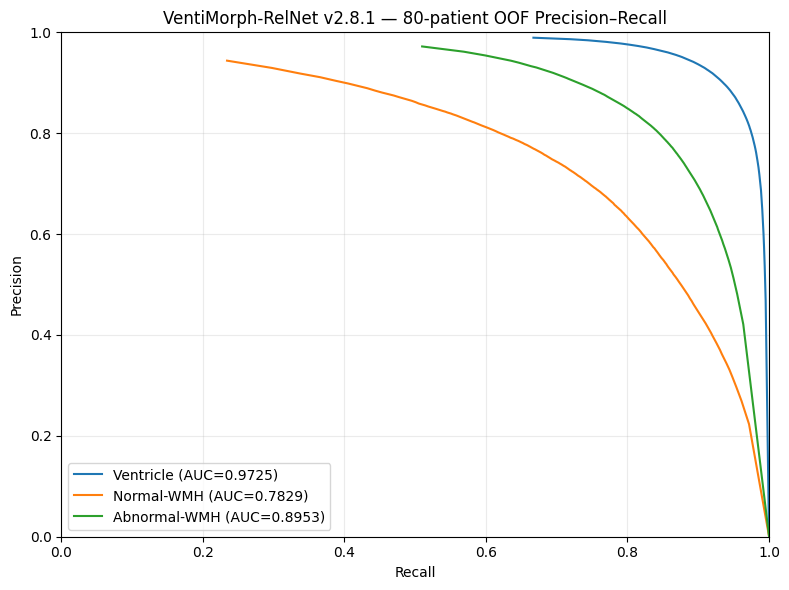

In [11]:
# Precision–Recall figure (primary probability curve for imbalanced segmentation).
plt.figure(figsize=(8, 6))

for class_name in CLASS_NAMES.values():
    class_curve = curve_df[curve_df["class"] == class_name]
    class_auc = auc_df.loc[
        auc_df["class"] == class_name,
        "pr_auc_approx",
    ].iloc[0]

    plt.plot(
        class_curve["recall"],
        class_curve["precision"],
        label=f"{class_name} (AUC={class_auc:.4f})",
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("VentiMorph-RelNet v2.8.1 — 80-patient OOF Precision–Recall")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "Figure13_OOF_precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight",
)
plt.savefig(
    FIGURE_DIR / "Figure13_OOF_precision_recall_curves.pdf",
    bbox_inches="tight",
)
plt.show()


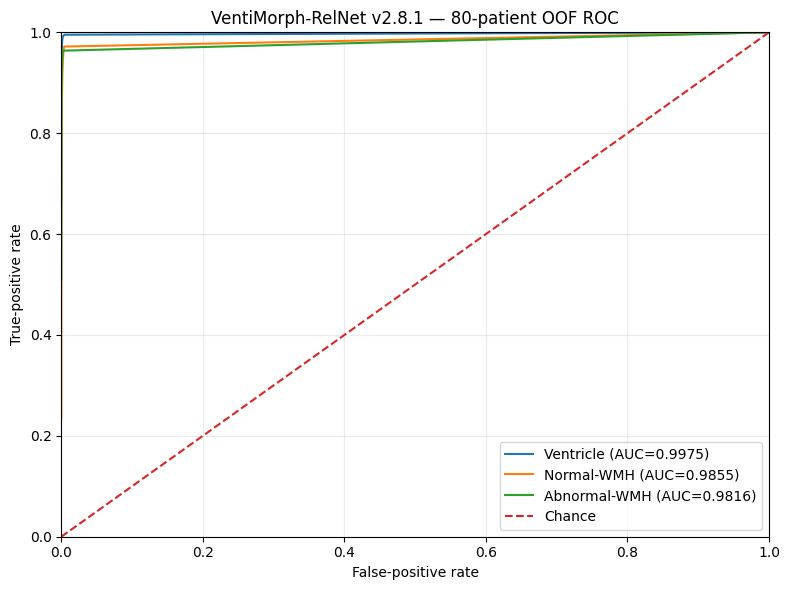

In [12]:
# ROC figure (supplementary; PR is more informative under severe voxel imbalance).
plt.figure(figsize=(8, 6))

for class_name in CLASS_NAMES.values():
    class_curve = curve_df[curve_df["class"] == class_name]
    class_auc = auc_df.loc[
        auc_df["class"] == class_name,
        "roc_auc_approx",
    ].iloc[0]

    plt.plot(
        class_curve["fpr"],
        class_curve["tpr"],
        label=f"{class_name} (AUC={class_auc:.4f})",
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title("VentiMorph-RelNet v2.8.1 — 80-patient OOF ROC")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "Figure14_OOF_ROC_curves.png",
    dpi=300,
    bbox_inches="tight",
)
plt.savefig(
    FIGURE_DIR / "Figure14_OOF_ROC_curves.pdf",
    bbox_inches="tight",
)
plt.show()


,oof_voxels,calibration_bins,expected_calibration_error,multiclass_brier_score
0,104005632,20,0.001369,0.003167


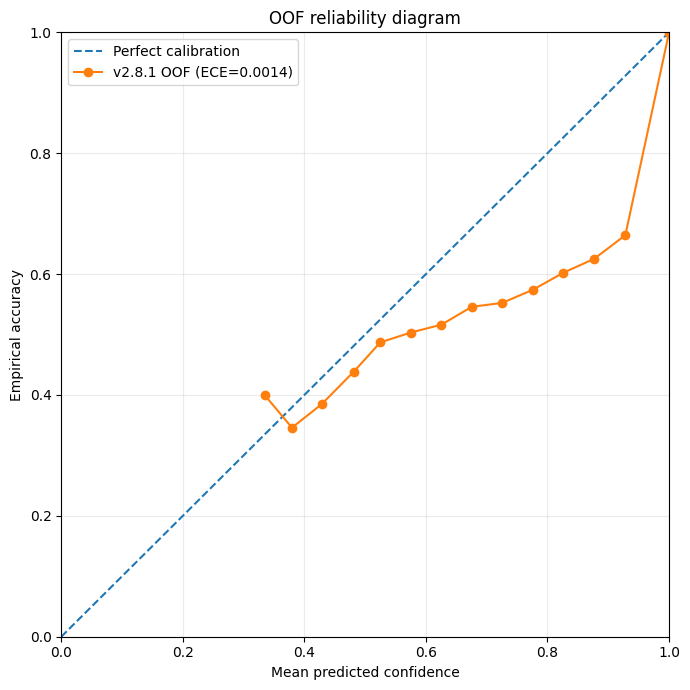

In [13]:
# Calibration / reliability
nonempty = calibration_count > 0

mean_confidence = np.divide(
    calibration_confidence_sum,
    calibration_count,
    out=np.full(CALIBRATION_BINS, np.nan),
    where=nonempty,
)

accuracy = np.divide(
    calibration_correct_sum,
    calibration_count,
    out=np.full(CALIBRATION_BINS, np.nan),
    where=nonempty,
)

ece = float(
    np.nansum(
        (calibration_count / max(calibration_count.sum(), 1))
        * np.abs(accuracy - mean_confidence)
    )
)

brier_score = float(
    brier_sum / max(total_voxels, 1)
)

calibration_df = pd.DataFrame({
    "bin": np.arange(CALIBRATION_BINS),
    "lower": np.arange(CALIBRATION_BINS) / CALIBRATION_BINS,
    "upper": (np.arange(CALIBRATION_BINS) + 1) / CALIBRATION_BINS,
    "count": calibration_count,
    "mean_confidence": mean_confidence,
    "accuracy": accuracy,
})

calibration_df.to_csv(
    TABLE_DIR / "step2_reliability_bins.csv",
    index=False,
)

calibration_summary = pd.DataFrame([{
    "oof_voxels": total_voxels,
    "calibration_bins": CALIBRATION_BINS,
    "expected_calibration_error": ece,
    "multiclass_brier_score": brier_score,
}])

calibration_summary.to_csv(
    TABLE_DIR / "step2_calibration_summary.csv",
    index=False,
)

display(calibration_summary)

plt.figure(figsize=(7, 7))
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.plot(
    mean_confidence[nonempty],
    accuracy[nonempty],
    marker="o",
    label=f"v2.8.1 OOF (ECE={ece:.4f})",
)
plt.xlabel("Mean predicted confidence")
plt.ylabel("Empirical accuracy")
plt.title("OOF reliability diagram")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "Figure15_OOF_reliability_diagram.png",
    dpi=300,
    bbox_inches="tight",
)
plt.savefig(
    FIGURE_DIR / "Figure15_OOF_reliability_diagram.pdf",
    bbox_inches="tight",
)
plt.show()


In [14]:
# Select cases from development-fold predictions.
# Selection is based only on already-computed OOF development metrics.
ranked = oof_patient_df.sort_values(
    "mean_foreground_dice",
    ascending=True,
).reset_index(drop=True)

weak_row = ranked.iloc[0]
median_row = ranked.iloc[len(ranked) // 2]
strong_row = ranked.iloc[-1]

selected_case_df = pd.DataFrame([
    {
        "category": "weak",
        **weak_row.to_dict(),
    },
    {
        "category": "representative_median",
        **median_row.to_dict(),
    },
    {
        "category": "strong",
        **strong_row.to_dict(),
    },
])

selected_case_df.to_csv(
    TABLE_DIR / "step2_selected_qualitative_cases.csv",
    index=False,
)

display(
    selected_case_df[
        [
            "category",
            "patient_id",
            "fold",
            "mean_foreground_dice",
            "ventricle_dice",
            "normal_wmh_dice",
            "abnormal_wmh_dice",
        ]
    ]
)


,category,patient_id,fold,mean_foreground_dice,ventricle_dice,normal_wmh_dice,abnormal_wmh_dice
0,weak,098,3,0.666229,0.947589,0.674286,0.376812
1,representative_median,096,3,0.815384,0.927667,0.703671,0.814815
2,strong,047,3,0.873902,0.938109,0.798865,0.884731


In [15]:
@torch.inference_mode()
def analyze_single_slice(model, patient_id, slice_index):
    patient_id = str(patient_id).zfill(3)
    row = manifest_by_id.loc[patient_id]

    # Construct ONE axial triplet rather than [whole-volume depth,9,H,W].
    inputs = np.concatenate([
        triplet(load_normalized_volume(row.flair), slice_index),
        triplet(load_normalized_volume(row.t1), slice_index),
        triplet(load_normalized_volume(row.t2), slice_index),
    ], axis=0)[None].astype(np.float32, copy=False)
    target = compose_target(row)

    input_slice = torch.from_numpy(
        np.ascontiguousarray(inputs)
    ).to(DEVICE)

    # Reproduce the spatial modality gate explicitly so it can be visualized.
    f = model.flair_stem(input_slice[:, 0:3])
    t1 = model.t1_stem(input_slice[:, 3:6])
    t2 = model.t2_stem(input_slice[:, 6:9])

    stacked = torch.cat([f, t1, t2], dim=1)
    spatial_gate = torch.softmax(
        model.fusion.gate(stacked),
        dim=1,
    )

    output = model(input_slice)
    probabilities = torch.softmax(
        output["segmentation_logits"].float(),
        dim=1,
    )
    prediction = probabilities.argmax(dim=1)

    final_relation = output["final_relation"]

    result = {
        "input_9ch": input_slice[0].float().cpu().numpy(),
        "probabilities": probabilities[0].cpu().numpy(),
        "prediction": prediction[0].cpu().numpy().astype(np.uint8),
        "target": target[:, :, slice_index].astype(np.uint8),
        "spatial_gate": spatial_gate[0].float().cpu().numpy(),
        "pooled_modality_weights": output["modality_weights"][0].float().cpu().numpy(),
    }

    for key in [
        "vent_prob",
        "near",
        "mid",
        "far",
        "soft_distance",
        "radial",
        "tangential",
    ]:
        value = final_relation.get(key)
        if value is not None:
            result[key] = value[0, 0].float().cpu().numpy()

    del input_slice, output, probabilities, prediction
    return result


def choose_informative_slice(patient_id):
    row = manifest_by_id.loc[str(patient_id).zfill(3)]
    target = compose_target(row)

    # Prefer slices containing WMH. If none exist, use all foreground.
    lesion_counts = (
        (target == 2).sum(axis=(0, 1))
        + (target == 3).sum(axis=(0, 1))
    )

    if lesion_counts.max() > 0:
        return int(np.argmax(lesion_counts))

    foreground_counts = (target > 0).sum(axis=(0, 1))
    return int(np.argmax(foreground_counts))


def build_error_map(target, prediction):
    # 0 correct; 1 false positive foreground; 2 false negative foreground;
    # 3 wrong foreground class.
    error = np.zeros_like(target, dtype=np.uint8)

    error[(target == 0) & (prediction > 0)] = 1
    error[(target > 0) & (prediction == 0)] = 2
    error[
        (target > 0)
        & (prediction > 0)
        & (target != prediction)
    ] = 3

    return error


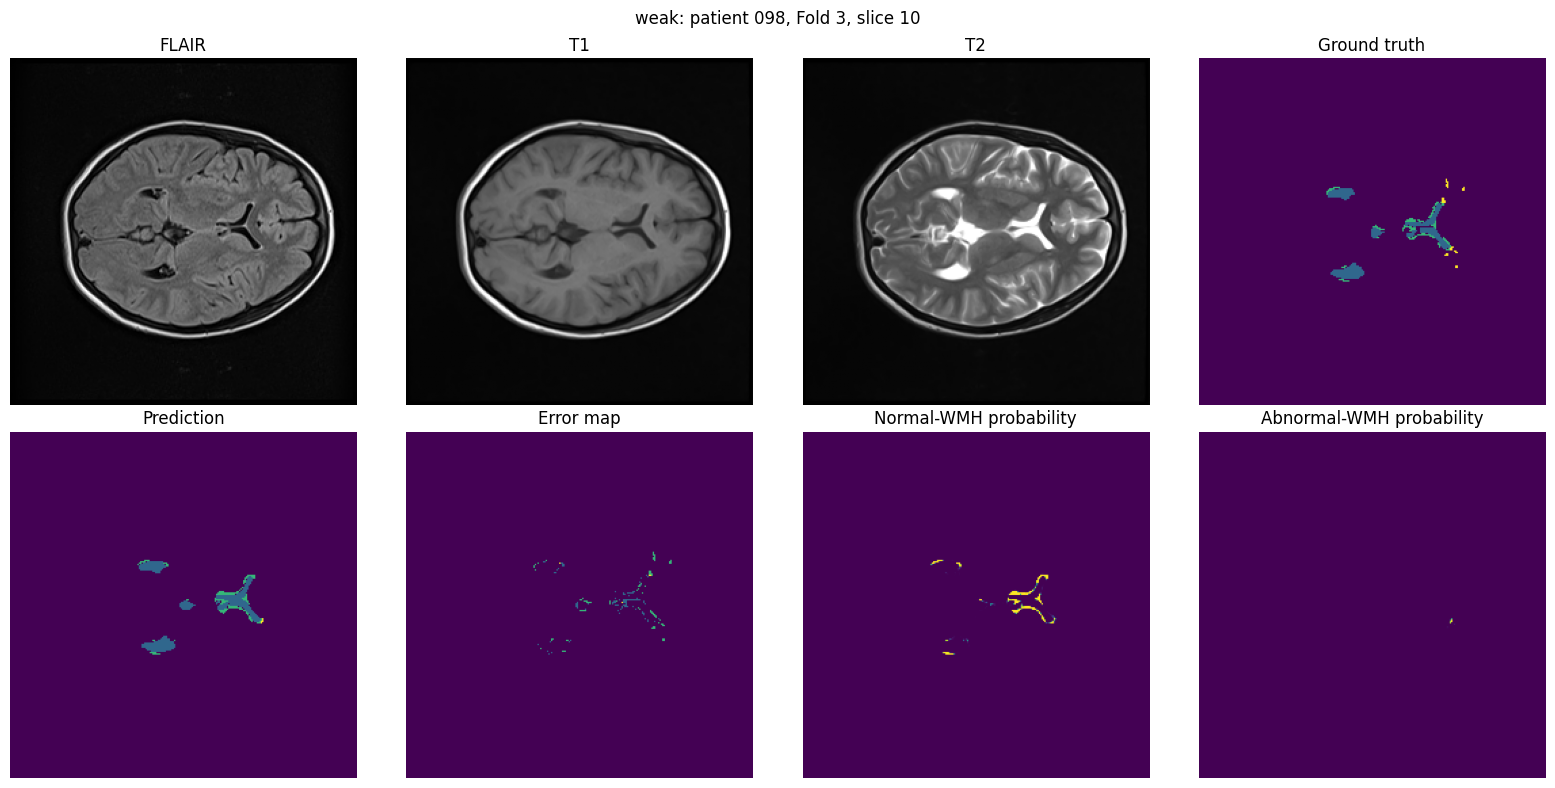

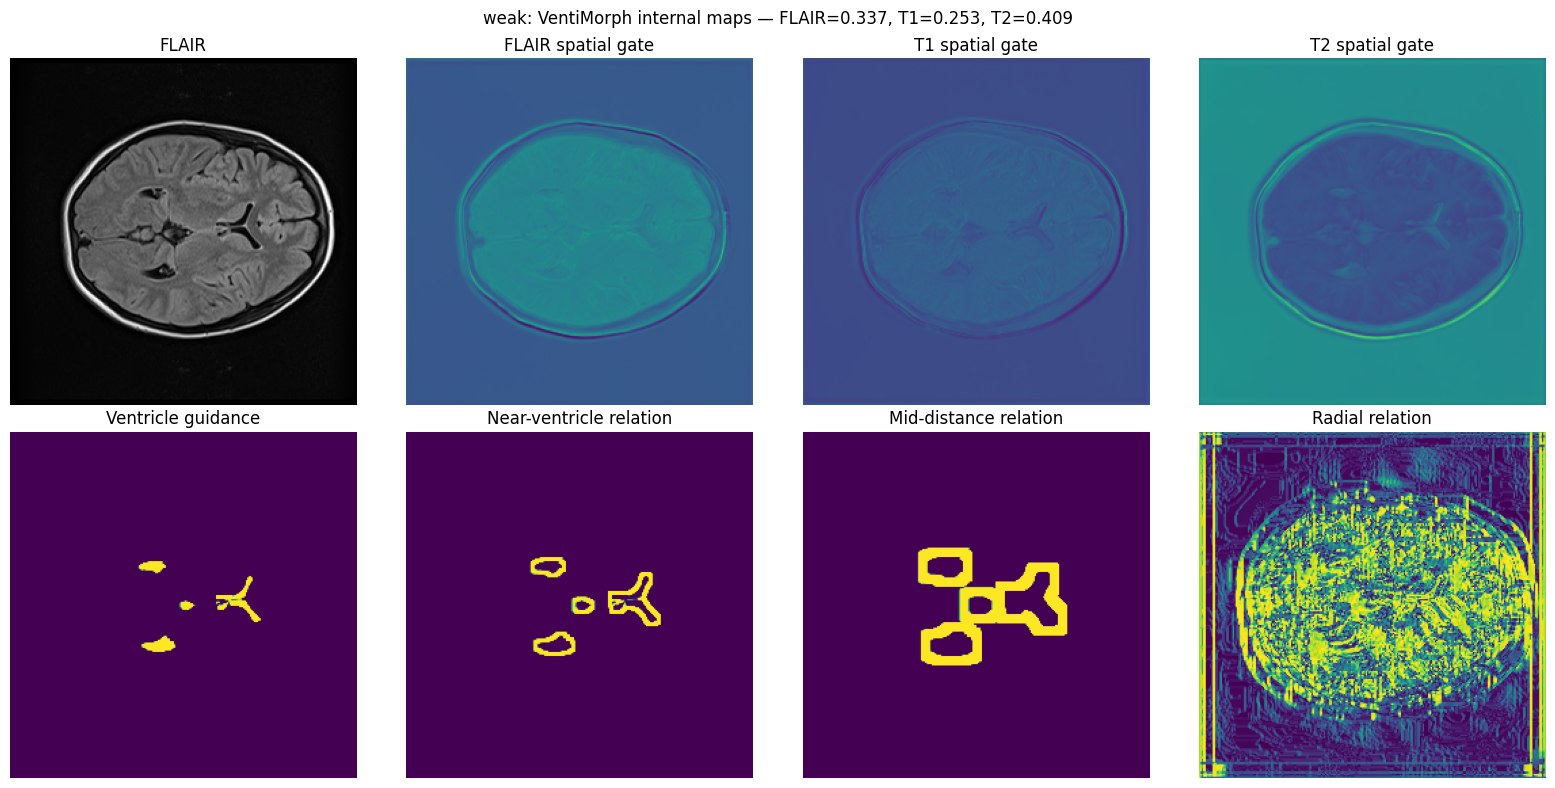

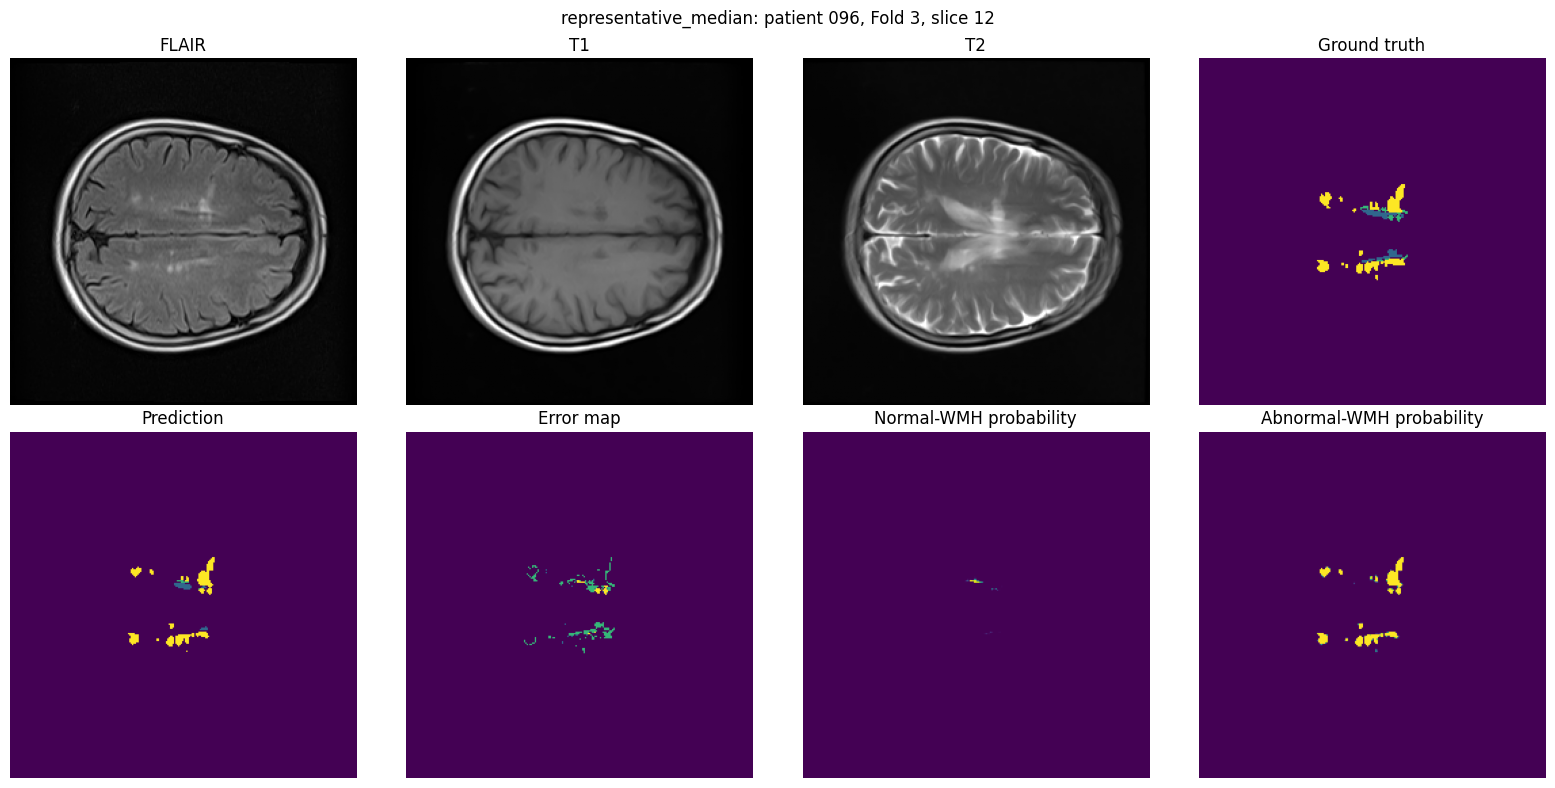

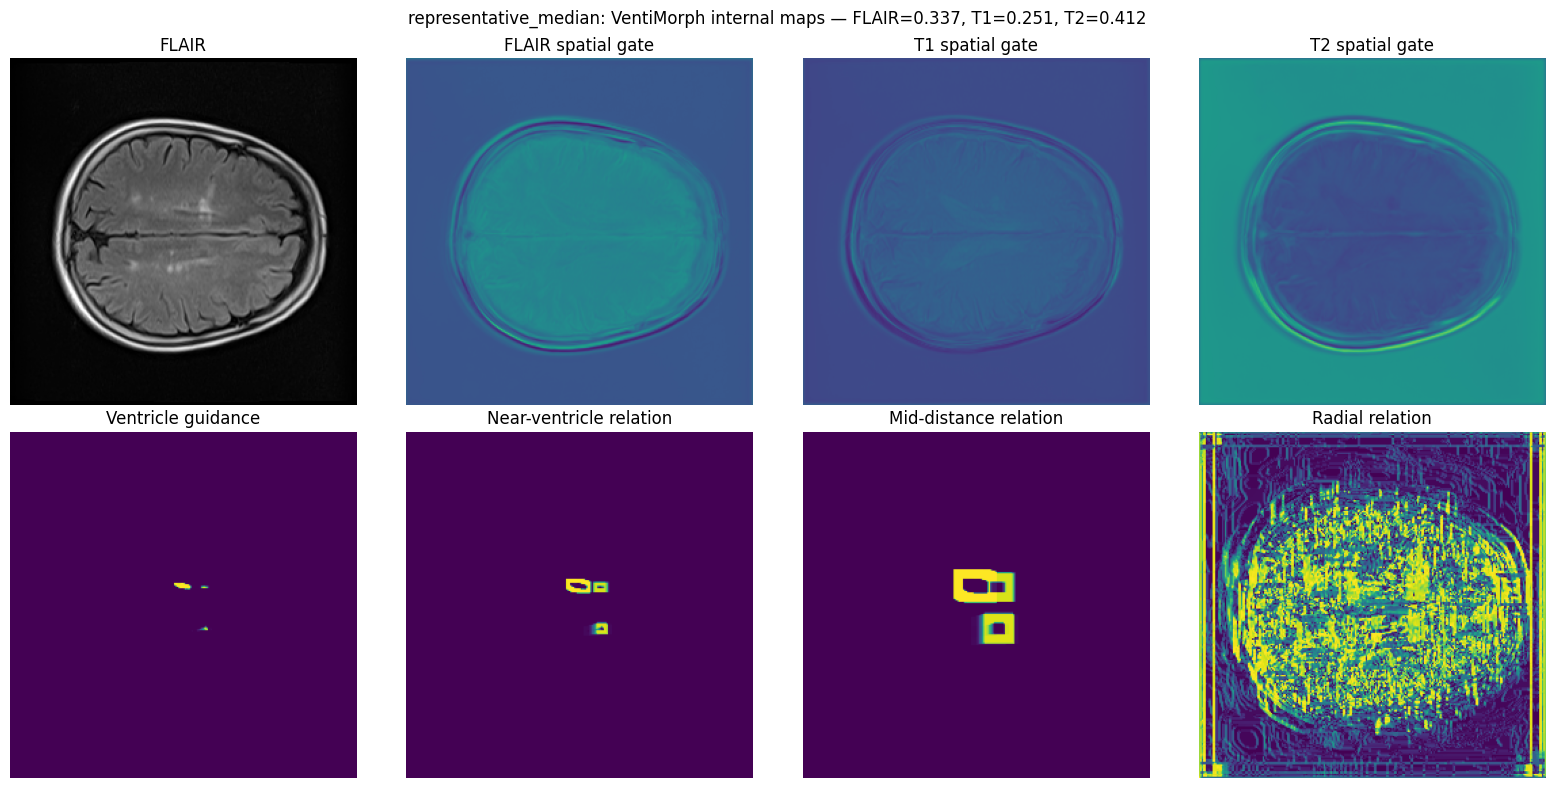

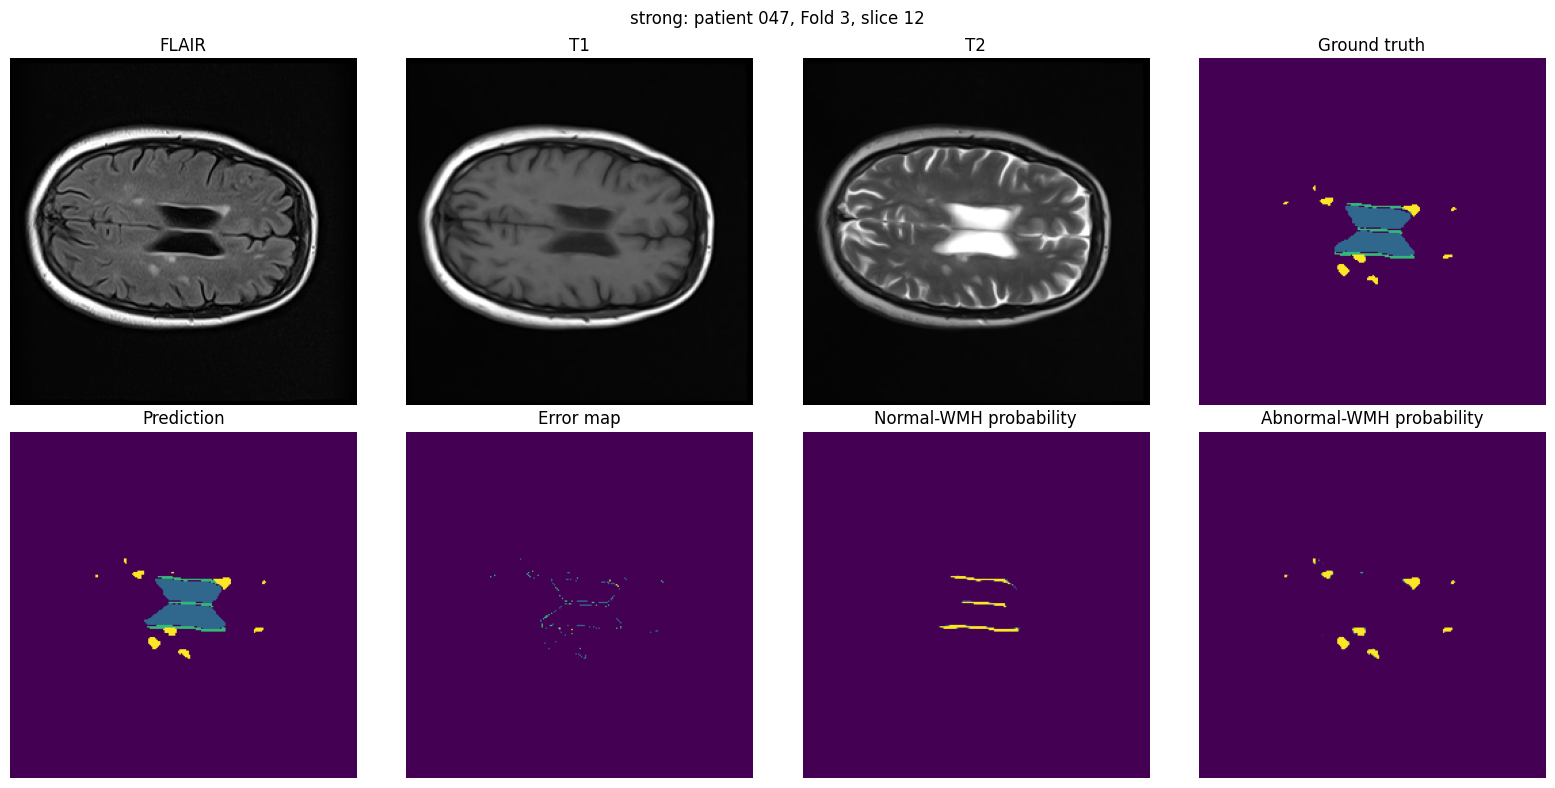

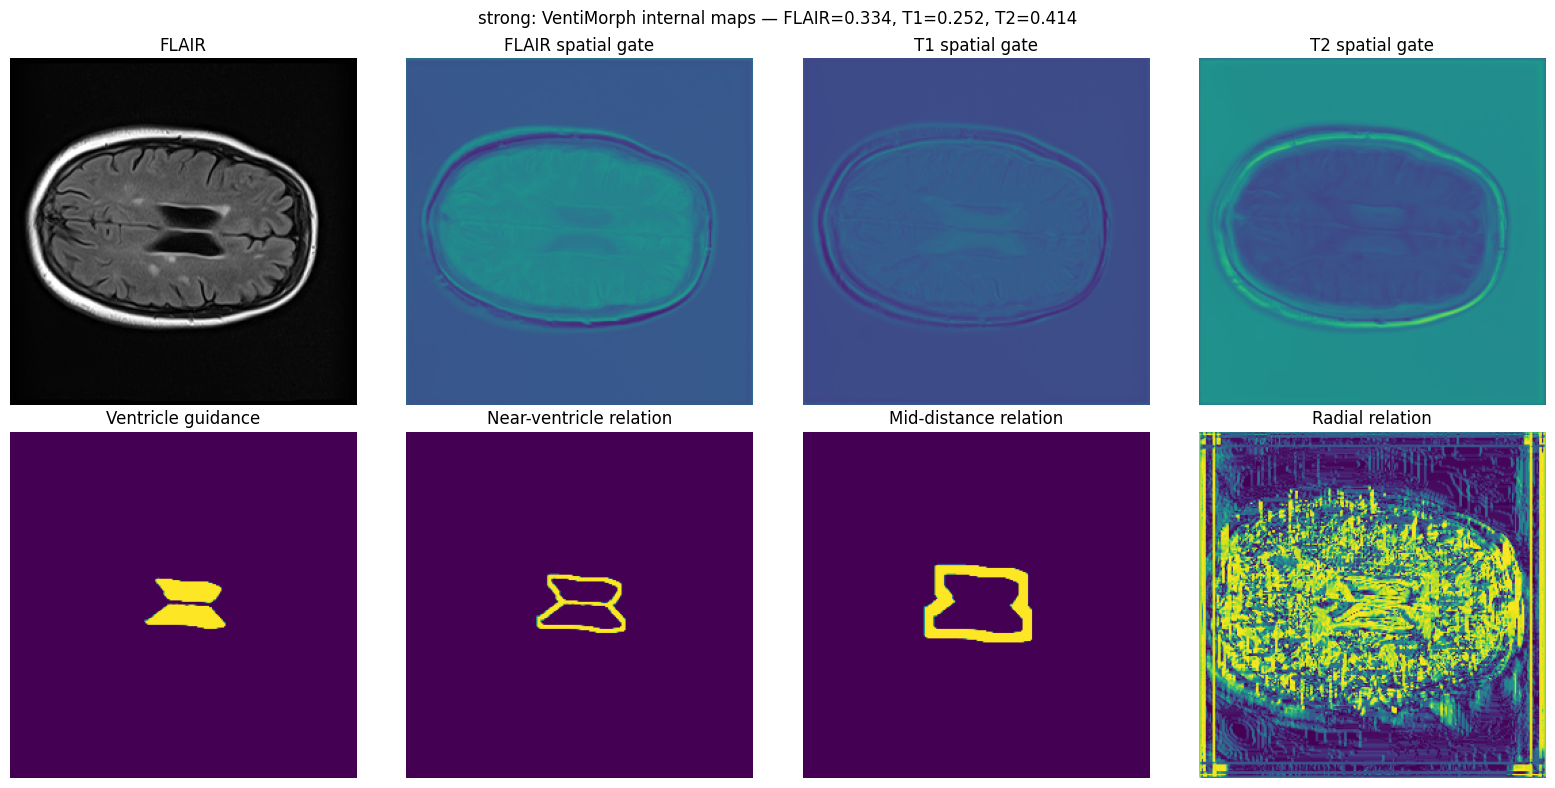

,category,patient_id,fold,slice_index,checkpoint_best_epoch,oof_mean_fg_dice,pooled_flair_weight,pooled_t1_weight,pooled_t2_weight
0,weak,098,3,10,50,0.666229,0.337435,0.253192,0.409373
1,representative_median,096,3,12,50,0.815384,0.336932,0.251318,0.411750
2,strong,047,3,12,50,0.873902,0.334102,0.252224,0.413674


In [16]:
# Generate qualitative + VentiMorph-specific XAI panels.
qualitative_audit_rows = []

for _, case_row in selected_case_df.iterrows():
    category = str(case_row["category"])
    patient_id = str(case_row["patient_id"]).zfill(3)
    fold = int(case_row["fold"])

    model, checkpoint, config, incompatible = build_model_from_checkpoint(
        CHECKPOINT_BUNDLES[fold]["checkpoint"],
        expected_fold=fold,
    )

    slice_index = choose_informative_slice(patient_id)
    result = analyze_single_slice(
        model,
        patient_id,
        slice_index,
    )

    target = result["target"]
    prediction = result["prediction"]
    error_map = build_error_map(target, prediction)

    # The center channel of each three-slice modality stack is the current slice.
    flair = result["input_9ch"][1]
    t1_image = result["input_9ch"][4]
    t2_image = result["input_9ch"][7]

    # -------------------------
    # Qualitative segmentation panel
    # -------------------------
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))

    axes[0, 0].imshow(flair, cmap="gray")
    axes[0, 0].set_title("FLAIR")
    axes[0, 1].imshow(t1_image, cmap="gray")
    axes[0, 1].set_title("T1")
    axes[0, 2].imshow(t2_image, cmap="gray")
    axes[0, 2].set_title("T2")
    axes[0, 3].imshow(target, vmin=0, vmax=3)
    axes[0, 3].set_title("Ground truth")

    axes[1, 0].imshow(prediction, vmin=0, vmax=3)
    axes[1, 0].set_title("Prediction")
    axes[1, 1].imshow(error_map, vmin=0, vmax=3)
    axes[1, 1].set_title("Error map")
    axes[1, 2].imshow(
        result["probabilities"][2],
        vmin=0,
        vmax=1,
    )
    axes[1, 2].set_title("Normal-WMH probability")
    axes[1, 3].imshow(
        result["probabilities"][3],
        vmin=0,
        vmax=1,
    )
    axes[1, 3].set_title("Abnormal-WMH probability")

    for ax in axes.ravel():
        ax.axis("off")

    fig.suptitle(
        f"{category}: patient {patient_id}, Fold {fold}, slice {slice_index}"
    )
    plt.tight_layout()
    qualitative_png = (
        QUAL_DIR
        / f"{category}_patient_{patient_id}_qualitative.png"
    )
    qualitative_pdf = qualitative_png.with_suffix(".pdf")
    plt.savefig(
        qualitative_png,
        dpi=300,
        bbox_inches="tight",
    )
    plt.savefig(
        qualitative_pdf,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    # -------------------------
    # Model-specific gating / relation panel
    # -------------------------
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))

    axes[0, 0].imshow(flair, cmap="gray")
    axes[0, 0].set_title("FLAIR")
    axes[0, 1].imshow(result["spatial_gate"][0], vmin=0, vmax=1)
    axes[0, 1].set_title("FLAIR spatial gate")
    axes[0, 2].imshow(result["spatial_gate"][1], vmin=0, vmax=1)
    axes[0, 2].set_title("T1 spatial gate")
    axes[0, 3].imshow(result["spatial_gate"][2], vmin=0, vmax=1)
    axes[0, 3].set_title("T2 spatial gate")

    relation_keys = [
        ("vent_prob", "Ventricle guidance"),
        ("near", "Near-ventricle relation"),
        ("mid", "Mid-distance relation"),
        ("radial", "Radial relation"),
    ]

    for ax, (key, title) in zip(axes[1], relation_keys):
        if key in result:
            ax.imshow(result[key], vmin=0, vmax=1)
        else:
            ax.text(
                0.5,
                0.5,
                "Not available",
                ha="center",
                va="center",
            )
        ax.set_title(title)

    for ax in axes.ravel():
        ax.axis("off")

    pooled = result["pooled_modality_weights"]
    fig.suptitle(
        f"{category}: VentiMorph internal maps — "
        f"FLAIR={pooled[0]:.3f}, T1={pooled[1]:.3f}, T2={pooled[2]:.3f}"
    )
    plt.tight_layout()

    xai_png = (
        QUAL_DIR
        / f"{category}_patient_{patient_id}_ventimorph_internal_maps.png"
    )
    xai_pdf = xai_png.with_suffix(".pdf")
    plt.savefig(
        xai_png,
        dpi=300,
        bbox_inches="tight",
    )
    plt.savefig(
        xai_pdf,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    qualitative_audit_rows.append({
        "category": category,
        "patient_id": patient_id,
        "fold": fold,
        "slice_index": slice_index,
        "checkpoint_best_epoch": checkpoint.get("best_epoch"),
        "oof_mean_fg_dice": case_row["mean_foreground_dice"],
        "pooled_flair_weight": float(pooled[0]),
        "pooled_t1_weight": float(pooled[1]),
        "pooled_t2_weight": float(pooled[2]),
    })

    del model, result
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

qualitative_audit_df = pd.DataFrame(
    qualitative_audit_rows
)
qualitative_audit_df.to_csv(
    TABLE_DIR / "step2_qualitative_xai_audit.csv",
    index=False,
)

display(qualitative_audit_df)


### Input attribution and perturbation checks

Integrated Gradients, modality replacement, refinement interventions and attribution-guided deletion are calculated on selected OOF cases. These diagnostics do not change the trained checkpoints.


In [17]:
import json
import math
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy import ndimage
import matplotlib.pyplot as plt

# Quantitative post-hoc XAI for unchanged, frozen OOF checkpoints.
# This uses the identical class-logit and ROI objective across input attributions.
XAI_INTEGRATION_STEPS = 16
XAI_CASES = ["weak", "representative_median", "strong"]
XAI_DELETION_FRACTIONS = [0.05, 0.10, 0.20]
XAI_RANDOM_REPEATS = 5
XAI_RANDOM_SEED = 2026
XAI_FIG_DIR = QUAL_DIR / "quantitative_xai"
XAI_FIG_DIR.mkdir(parents=True, exist_ok=True)


def xai_roi_objective(model, x, class_id, roi_mask, use_logits=True):
    logits = model(x)["segmentation_logits"].float()
    values = logits if use_logits else torch.softmax(logits, dim=1)
    return ((values[:, class_id] * roi_mask).sum() /
            roi_mask.sum().clamp_min(1.0))


def integrated_gradients_segmentation(model, x, class_id, roi_mask, steps=12):
    """Trapezoidal IG for mean class logit in a PRESELECTED reference-lesion ROI.

    The reference mask is used to define the score region for an offline
    evaluation, NOT given as an input to the segmentation model.
    Input baseline = zero in the notebook's normalized feature space.
    """
    if x.ndim != 4 or x.shape[1] != 9 or x.shape[0] != 1:
        raise ValueError("Expecting one 9-channel 2.5D slice")
    if roi_mask.sum().item() == 0:
        raise ValueError("Empty ROI for the requested class")
    baseline = torch.zeros_like(x)
    delta = x - baseline
    accumulated = torch.zeros_like(x)
    with torch.enable_grad():
        for j in range(steps + 1):
            alpha = float(j) / steps
            xt = (baseline + alpha * delta).detach().requires_grad_(True)
            target_score = xai_roi_objective(model, xt, class_id, roi_mask,
                                             use_logits=True)
            grad, = torch.autograd.grad(target_score, xt, retain_graph=False)
            factor = 0.5 if j in (0, steps) else 1.0
            accumulated.add_(grad.detach(), alpha=factor)
            del xt, target_score, grad
    attribution = delta * accumulated / float(steps)
    with torch.no_grad():
        score_x = xai_roi_objective(model, x, class_id, roi_mask, True).item()
        score_0 = xai_roi_objective(model, baseline, class_id, roi_mask, True).item()
    completeness_residual = float(attribution.sum().item() - (score_x-score_0))
    return attribution.detach(), completeness_residual


@torch.no_grad()
def xai_mean_probability(model, x, class_id, roi_mask):
    return float(xai_roi_objective(model, x, class_id, roi_mask,
                                 use_logits=False).item())


@torch.no_grad()
def xai_modality_removal(model, x, class_id, roi_mask):
    """Mask one of the three normalized MRI modalities at a time (not retraining)."""
    original = xai_mean_probability(model, x, class_id, roi_mask)
    results = {}
    for name, first_channel in [("FLAIR",0),("T1",3),("T2",6)]:
        masked = x.clone()
        masked[:, first_channel:first_channel+3, :, :] = 0
        masked_prob = xai_mean_probability(model, masked, class_id, roi_mask)
        results[name] = {"masked_probability": masked_prob,
                         "confidence_drop": original - masked_prob}
        del masked
    return original, results


@torch.no_grad()
def xai_disable_refiner_residuals(model, x, class_id, roi_mask):
    """Sensitivity to saved refinement residuals; NOT an equivalent retrained ablation."""
    original = xai_mean_probability(model, x, class_id, roi_mask)
    modules = (model.mid_guide, model.final_guide)
    saved = [float(m.max_residual) for m in modules]
    try:
        for module in modules:
            module.max_residual = 0.0
        without_refinement = xai_mean_probability(model, x, class_id, roi_mask)
    finally:
        for module, amplitude in zip(modules, saved):
            module.max_residual = amplitude
    return original - without_refinement


def xai_fixed_mask_deletion(model, x, class_id, roi_mask, attr_map,
                            fractions=(0.05,0.1,0.2), repeats=3,
                            random_seed=2026):
    """Compare confidence drop for high-IG vs random pixels inside lesion halo.

    Zero replacement and lesion-halo restriction may create out-of-distribution
    inputs; therefore report this as a perturbation test, not causal proof.
    """
    focus = ndimage.binary_dilation(roi_mask.detach().cpu().numpy()[0] > 0,
                                    iterations=12)
    flat_candidates = np.flatnonzero(focus.ravel())
    if len(flat_candidates) < 25:
        raise ValueError("Not enough candidates for deletion probe")
    weighted = attr_map.ravel()[flat_candidates]
    sorted_candidates = flat_candidates[np.argsort(-weighted, kind="stable")]
    rng = np.random.default_rng(random_seed)
    baseline_score = xai_mean_probability(model, x, class_id, roi_mask)
    H, W = focus.shape
    rows=[]
    for frac in fractions:
        n = max(1, int(round(len(flat_candidates) * float(frac))))
        salient = sorted_candidates[:n]
        selected = torch.zeros((H*W,), device=x.device, dtype=torch.bool)
        selected[torch.as_tensor(salient, device=x.device)] = True
        masked = x.clone().reshape(1,9,-1)
        masked[:, :, selected] = 0
        ig_prob = xai_mean_probability(model, masked.reshape_as(x), class_id, roi_mask)
        random_probs=[]
        for _ in range(repeats):
            pick = rng.choice(flat_candidates, size=n, replace=False)
            mask_rand = torch.zeros((H*W,), device=x.device, dtype=torch.bool)
            mask_rand[torch.as_tensor(pick, device=x.device)] = True
            random_input = x.clone().reshape(1,9,-1)
            random_input[:, :, mask_rand] = 0
            random_probs.append(xai_mean_probability(model,
                   random_input.reshape_as(x),class_id,roi_mask))
        rows.append({"fraction_of_lesion_halo_removed":float(frac),
                     "baseline_probability":baseline_score,
                     "IG_probability_after_removal":ig_prob,
                     "IG_probability_drop":baseline_score-ig_prob,
                     "random_probability_mean":float(np.mean(random_probs)),
                     "random_probability_drop_mean":float(baseline_score-np.mean(random_probs))})
    return rows


def run_case_quant_xai(case, fold_bundles, patient_lookup, device):
    category = str(case["category"])
    pid = str(case["patient_id"]).zfill(3)
    fold = int(case["fold"])
    model, checkpoint, config, incompatible = build_model_from_checkpoint(
        fold_bundles[fold]["checkpoint"], expected_fold=fold)
    try:
        row = patient_lookup.loc[pid]
        target = compose_target(row)
        # Prefer the axial slice with most abnormal WMH, or normal WMH otherwise.
        ab_counts = (target==3).sum(axis=(0,1))
        normal_counts = (target==2).sum(axis=(0,1))
        if ab_counts.max()>0:
            class_id,z=3,int(np.argmax(ab_counts))
        elif normal_counts.max()>0:
            class_id,z=2,int(np.argmax(normal_counts))
        else:
            raise ValueError(f"No lesion-class voxels for patient {pid}")
        # Load only the selected three-slice stack, not all 2.5D slices.
        # This avoids a large [depth, 9, H, W] temporary array on Kaggle.
        selected_stack = np.concatenate([
            triplet(load_normalized_volume(row.flair), z),
            triplet(load_normalized_volume(row.t1), z),
            triplet(load_normalized_volume(row.t2), z),
        ], axis=0)[None].astype(np.float32, copy=False)
        x=torch.from_numpy(np.ascontiguousarray(selected_stack)).to(
            device=device, dtype=torch.float32)
        del selected_stack
        roi=torch.from_numpy(np.ascontiguousarray(
            (target[:,:,z]==class_id)[None,:,:].astype('float32'))).to(device)
        assert roi.shape==x.shape[:1]+x.shape[2:]
        model.eval()
        attribution, residual=integrated_gradients_segmentation(
            model,x,class_id,roi,XAI_INTEGRATION_STEPS)
        ig_abs=attribution.abs().detach().cpu().numpy()[0]
        ig_map=ig_abs.sum(axis=0)
        modality_l1=np.array([ig_abs[0:3].sum(),ig_abs[3:6].sum(),ig_abs[6:9].sum()],dtype=float)
        modality_share=modality_l1/max(float(modality_l1.sum()),1e-12)
        original_prob, drops=xai_modality_removal(model,x,class_id,roi)
        refiner_drop=xai_disable_refiner_residuals(model,x,class_id,roi)
        deletion=xai_fixed_mask_deletion(model,x,class_id,roi,ig_map,
                     XAI_DELETION_FRACTIONS,XAI_RANDOM_REPEATS,
                     random_seed=XAI_RANDOM_SEED+fold)
        for d in deletion:
            d.update({"category":category,"patient_id":pid,"fold":fold,
                      "class_id":class_id,"slice_index":z})
        # Relative completeness error should shrink with more IG steps.
        with torch.no_grad():
            base_input = torch.zeros_like(x)
            score_span = float((xai_roi_objective(model,x,class_id,roi,True) -
                    xai_roi_objective(model,base_input,class_id,roi,True)).abs().item())
        report = {"category":category,"patient_id":pid,"fold":fold,
                  "slice_index":z,"target_class":class_id,
                  "ig_relative_completeness_error":abs(residual)/max(score_span,1e-6),
                  "target_roi_voxels_in_slice":int(roi.sum().item()),
                  "original_roi_class_probability":original_prob,
                  "ig_logit_completeness_residual":residual,
                  "ig_flair_l1_fraction":float(modality_share[0]),
                  "ig_t1_l1_fraction":float(modality_share[1]),
                  "ig_t2_l1_fraction":float(modality_share[2]),
                  "flair_removal_prob_drop":drops['FLAIR']['confidence_drop'],
                  "t1_removal_prob_drop":drops['T1']['confidence_drop'],
                  "t2_removal_prob_drop":drops['T2']['confidence_drop'],
                  "refiner_residual_removal_prob_drop":refiner_drop}
        # Three-panel XAI figure with identical anatomy and a fixed target ROI.
        image=x[0,1].detach().cpu().numpy()
        roinp=roi[0].detach().cpu().numpy().astype(bool)
        lo,hi=np.percentile(image,[1,99])
        normed=np.clip((image-lo)/max(hi-lo,1e-6),0,1)
        ig_vis=np.clip(ig_map/max(np.percentile(ig_map,99.5),1e-10),0,1)
        fig,axs=plt.subplots(1,3,figsize=(11.6,3.9),layout='constrained')
        axs[0].imshow(normed,cmap='gray',vmin=0,vmax=1)
        axs[0].set_title('FLAIR (central slice)')
        axs[1].imshow(normed,cmap='gray',vmin=0,vmax=1)
        axs[1].contour(roinp,levels=[.5],colors=['#14d68a'],linewidths=.8)
        axs[1].set_title('Reference lesion ROI (outline)')
        axs[2].imshow(normed,cmap='gray',vmin=0,vmax=1)
        heat=axs[2].imshow(ig_vis,cmap='inferno',vmin=0,vmax=1,alpha=.62)
        axs[2].set_title('ROI-targeted Integrated Gradients')
        for ax in axs: ax.axis('off')
        fig.suptitle(f'{category} OOF case · patient {pid} · fold {fold} · '
                     f'slice {z} · class {class_id}', fontsize=11, weight='bold')
        for ext in ('png','pdf'):
            fig.savefig(XAI_FIG_DIR/f'XAI_IG_{category}_patient_{pid}.{ext}',
                dpi=300 if ext=='png' else None,bbox_inches='tight',facecolor='white')
        plt.show(); plt.close(fig)
        # Modality-specific attributions: 3 triplet-groups from the same IG tensor.
        maps=[ig_abs[j:j+3].sum(axis=0) for j in (0,3,6)]
        fig, axs = plt.subplots(1,4,figsize=(13.5,3.6),layout="constrained")
        axs[0].imshow(normed,cmap="gray",vmin=0,vmax=1)
        axs[0].contour(roinp,levels=[.5],colors=["#00e0a8"],linewidths=.8)
        axs[0].set_title("FLAIR + reference ROI")
        for ax,name,m in zip(axs[1:],["FLAIR IG","T1 IG","T2 IG"],maps):
            ax.imshow(normed,cmap="gray",vmin=0,vmax=1)
            a=np.clip(m/max(np.percentile(m,99.5),1e-10),0,1)
            ax.imshow(a,cmap="inferno",vmin=0,vmax=1,alpha=.64)
            ax.set_title(name)
        for ax in axs: ax.axis("off")
        for ext in ("png","pdf"):
            fig.savefig(XAI_FIG_DIR/f"XAI_modality_maps_{category}_patient_{pid}.{ext}",
                        dpi=300 if ext=="png" else None,bbox_inches="tight")
        plt.show(); plt.close(fig)
        # Faithfulness probe: top-attribution deletion vs matched random deletion.
        fractions=[float(d["fraction_of_lesion_halo_removed"]) for d in deletion]
        igdrop=[float(d["IG_probability_drop"]) for d in deletion]
        randdrop=[float(d["random_probability_drop_mean"]) for d in deletion]
        fig,ax=plt.subplots(figsize=(5.7,4))
        ax.plot([100*f for f in fractions],igdrop,marker="o",label="Top-IG pixels")
        ax.plot([100*f for f in fractions],randdrop,marker="s",label="Random pixels (mean)")
        ax.axhline(0,color="#777777",linewidth=.9)
        ax.set_xlabel("Lesion-halo pixels set to zero (%)")
        ax.set_ylabel("Class-probability decrease within ROI")
        ax.set_title(f"Deletion sensitivity · {category} · patient {pid}")
        ax.legend(frameon=False)
        ax.grid(alpha=.2)
        fig.tight_layout()
        for ext in ("png","pdf"):
            fig.savefig(XAI_FIG_DIR/f"XAI_deletion_{category}_patient_{pid}.{ext}",
                        dpi=300 if ext=="png" else None,bbox_inches="tight")
        plt.show(); plt.close(fig)
        return report,deletion
    finally:
        del model
        import gc
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()




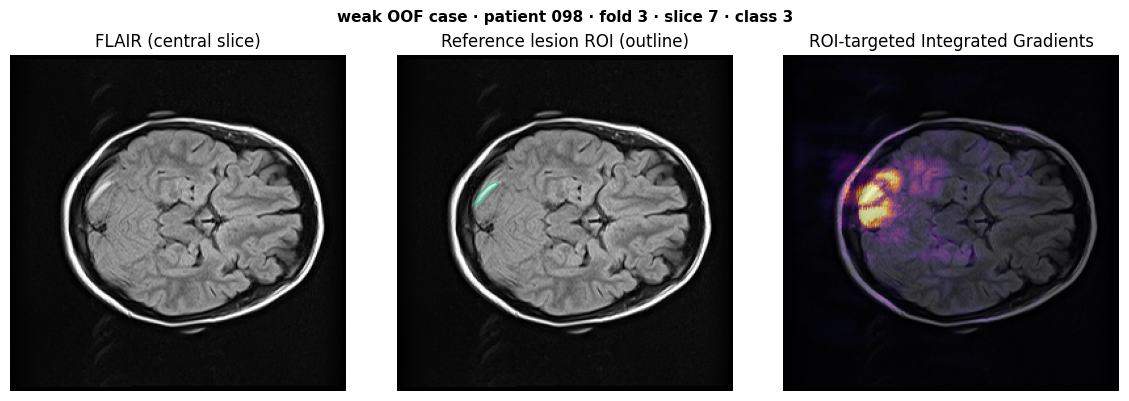

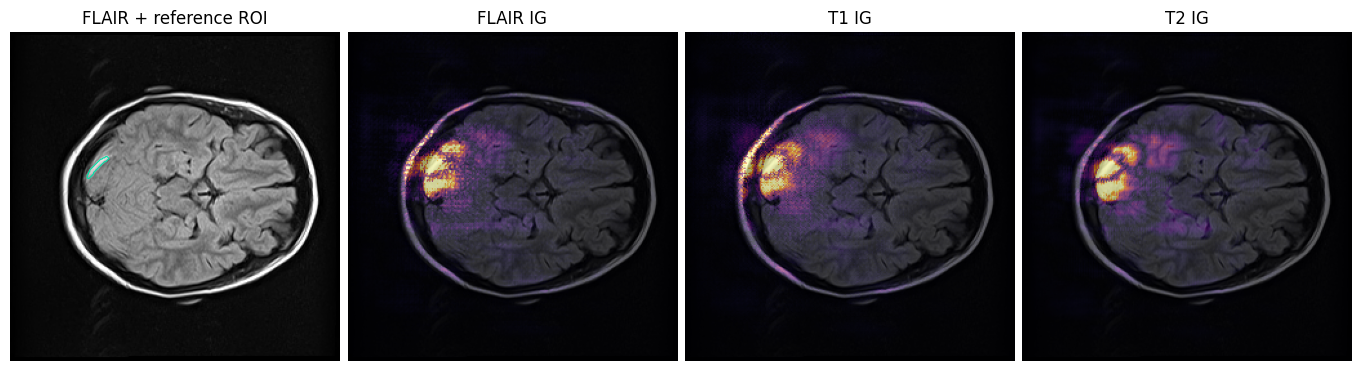

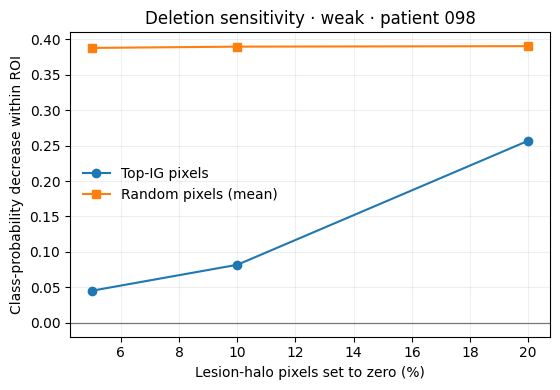

XAI: 098 class 3 ROI probability 0.3902


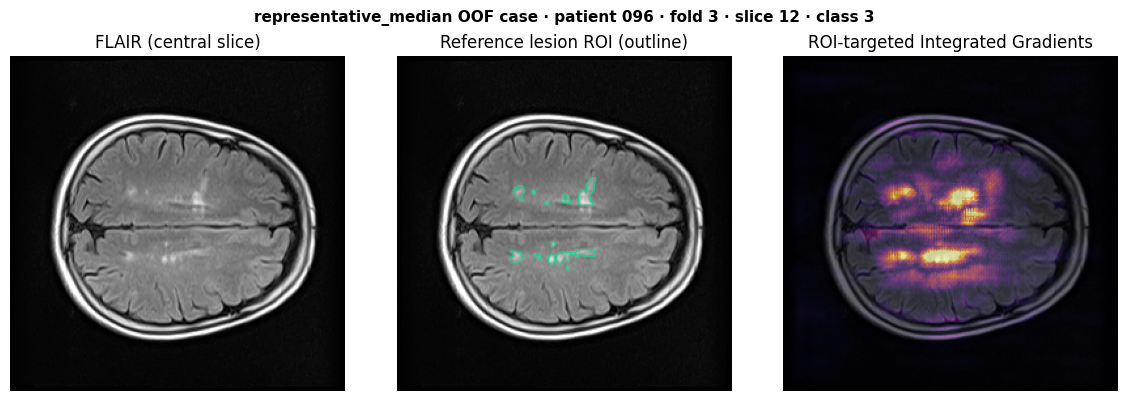

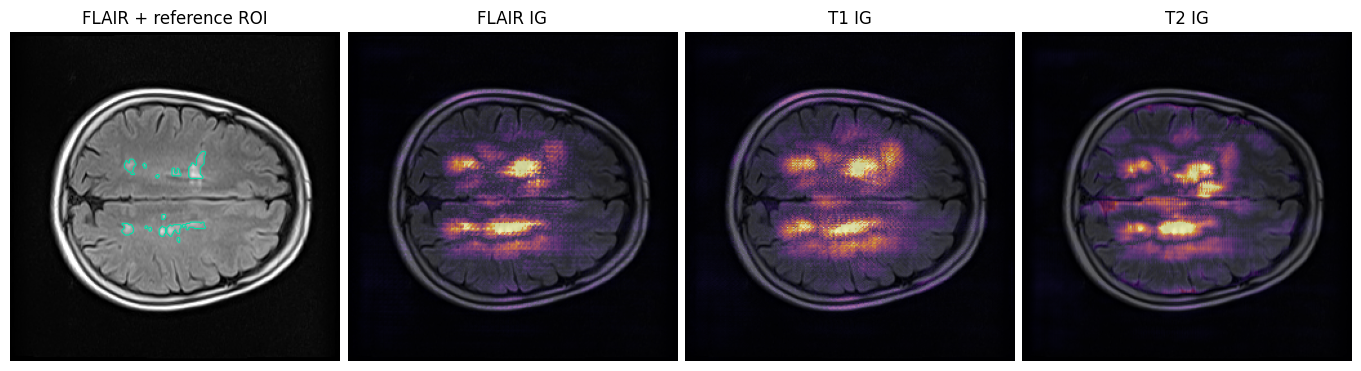

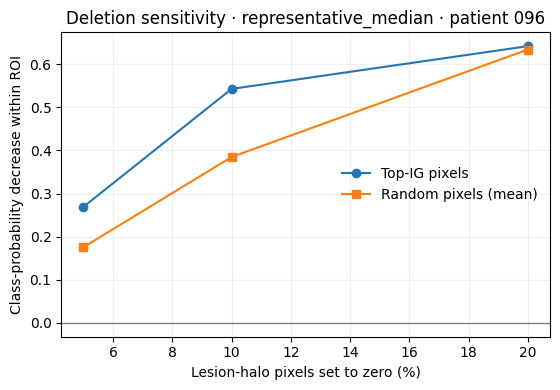

XAI: 096 class 3 ROI probability 0.7482


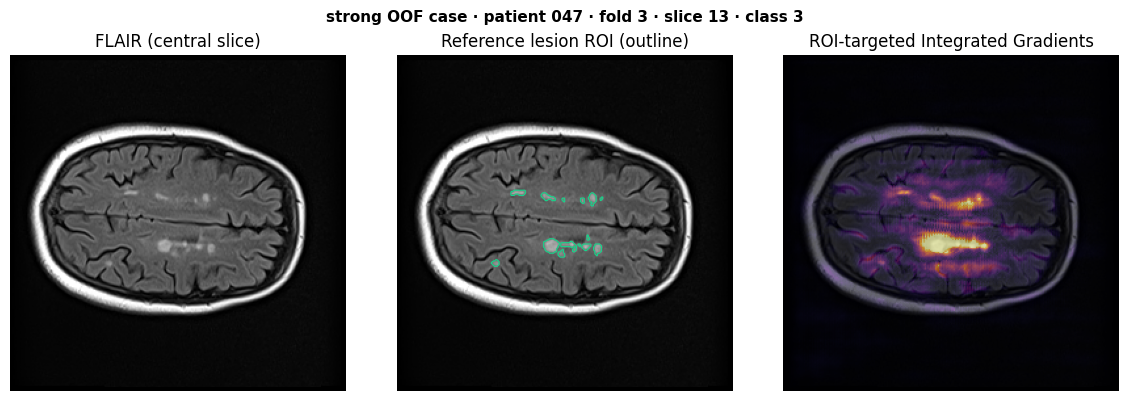

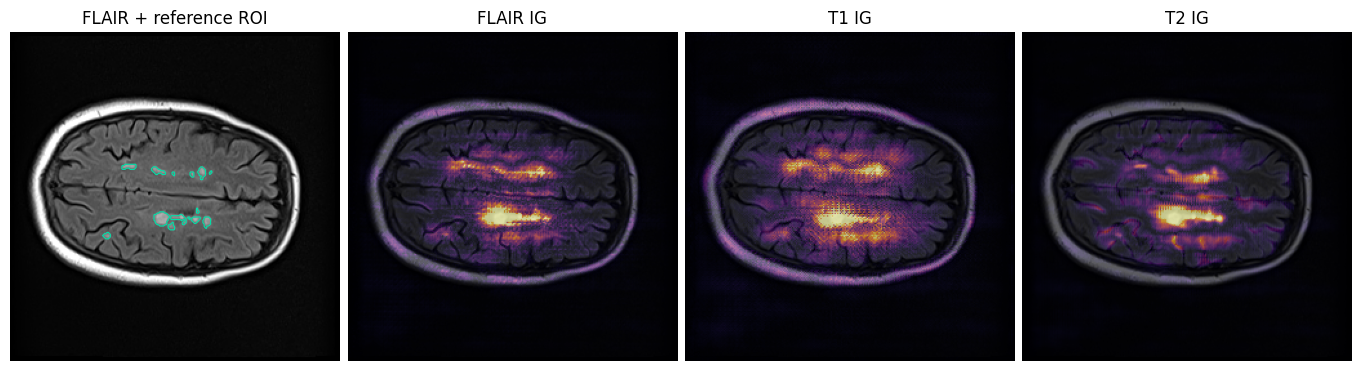

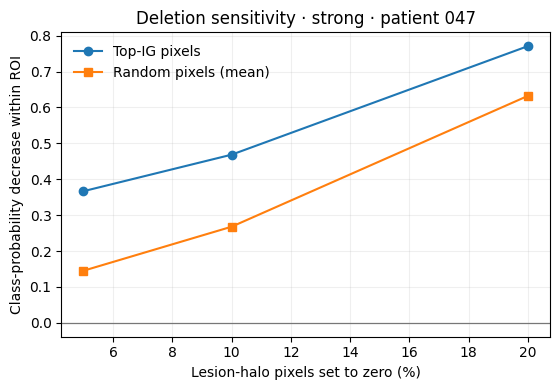

XAI: 047 class 3 ROI probability 0.9475


,category,patient_id,fold,slice_index,target_class,ig_relative_completeness_error,target_roi_voxels_in_slice,original_roi_class_probability,ig_logit_completeness_residual,ig_flair_l1_fraction,ig_t1_l1_fraction,ig_t2_l1_fraction,flair_removal_prob_drop,t1_removal_prob_drop,t2_removal_prob_drop,refiner_residual_removal_prob_drop
0,weak,098,3,7,3,18790.700182,75,0.390158,140501.241581,0.179123,0.151449,0.669428,0.390158,-0.165615,0.390133,-0.197023
1,representative_median,096,3,12,3,12790.035513,525,0.748177,-144053.200424,0.181072,0.169303,0.649624,0.748176,0.039422,-0.047688,-0.059410
2,strong,047,3,13,3,15504.848956,393,0.947467,-224775.122086,0.176717,0.133947,0.689336,0.947465,0.311500,0.092091,-0.015094


,fraction_of_lesion_halo_removed,baseline_probability,IG_probability_after_removal,IG_probability_drop,random_probability_mean,random_probability_drop_mean,category,patient_id,fold,class_id,slice_index
0,0.05,0.390158,0.344830,0.045328,0.002523,0.387635,weak,098,3,3,7
1,0.10,0.390158,0.308246,0.081912,0.000723,0.389435,weak,098,3,3,7
2,0.20,0.390158,0.133392,0.256766,0.000052,0.390106,weak,098,3,3,7
3,0.05,0.748177,0.478820,0.269357,0.572505,0.175671,representative_median,096,3,3,12
4,0.10,0.748177,0.205347,0.542830,0.363335,0.384842,representative_median,096,3,3,12
5,0.20,0.748177,0.106137,0.642040,0.113984,0.634193,representative_median,096,3,3,12
6,0.05,0.947467,0.580686,0.366780,0.802182,0.145284,strong,047,3,3,13
7,0.10,0.947467,0.479010,0.468456,0.679621,0.267845,strong,047,3,3,13
8,0.20,0.947467,0.176817,0.770649,0.315396,0.632071,strong,047,3,3,13


698

In [18]:
# Use OOF development cases only.
xai_case_rows=[]
xai_deletion_rows=[]
for cat in XAI_CASES:
    case=selected_case_df.loc[selected_case_df['category']==cat]
    if len(case)!=1:
        raise RuntimeError(f'Expected one case for {cat}, found {len(case)}')
    result, curves = run_case_quant_xai(case.iloc[0], CHECKPOINT_BUNDLES,
                                        manifest_by_id, DEVICE)
    xai_case_rows.append(result)
    xai_deletion_rows.extend(curves)
    print('XAI:',result['patient_id'], 'class',result['target_class'],
          'ROI probability',round(result['original_roi_class_probability'],4))

xai_case_metrics_df=pd.DataFrame(xai_case_rows)
xai_deletion_df=pd.DataFrame(xai_deletion_rows)
xai_case_metrics_df.to_csv(TABLE_DIR/'step2_quantitative_xai_cases.csv',index=False)
xai_deletion_df.to_csv(TABLE_DIR/'step2_quantitative_xai_deletion.csv',index=False)
display(xai_case_metrics_df)
display(xai_deletion_df)
(OUTPUT_DIR/'step2_quantitative_xai_protocol.json').write_text(json.dumps({
    'cohort':'OOF development patients only',
    'case_selection':'weak, median and strong selected on OOF Dice',
    'IG_steps':XAI_INTEGRATION_STEPS,
    'random_repeats':XAI_RANDOM_REPEATS,
    'IG_score':'mean segmentation class logit inside fixed reference lesion ROI',
    'baseline':'all channels zero after intensity normalization',
    'modality_ablation':'replace all 3 neighboring-slice channels for one modality with zero',
    'refinement_test':'disable mid/final residual amplitudes only during inference; not retrained ablation',
    'deletion':'top absolute-IG pixels vs seeded random pixels in a 12-pixel lesion halo',
    'clinical_interpretation':'exploratory; perturbations may be out of distribution; not causal proof',
},indent=2),encoding='utf-8')


## Ventricle-relation attribution (VRAA)

Four frozen-model inference settings isolate the middle and final refinement effects. Two-factor Shapley terms describe the contributions to the prediction-probability difference; the interaction term captures their non-additivity.

Ventricular-distance bands are computed from reference masks for retrospective evaluation only, not provided to the model. Attribution analysis targets the refinement-induced change in lesion-class logits. Results are exploratory and require quantitative validation before publication claims.


In [19]:
"""VRAA: exploratory ventricle-relation attribution analysis for VentiMorph-RelNet v2.8.1.

Requires a loaded VentiMorphRelNet model with .mid_guide and .final_guide.
The caller provides frozen OOF checkpoints and registered MS3SEG data.
This is an inference-time analysis, not causal identification or a trained ablation.
"""
from contextlib import contextmanager
from pathlib import Path
import gc
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
import torch
import torch.nn.functional as F

MODES = ('both', 'mid_only', 'final_only', 'off')
DISTANCE_BANDS_MM = ((0.0, 3.0, '0-3 mm'),
                     (3.0, 10.0, '3-10 mm'),
                     (10.0, np.inf, '>10 mm'))

@contextmanager
def refinement_mode(model, mode):
    """Temporarily alter scalar residual amplitudes; restore even on error."""
    if mode not in MODES:
        raise ValueError(f'Unknown refinement mode: {mode}')
    if not hasattr(model, 'mid_guide') or not hasattr(model, 'final_guide'):
        raise TypeError('Expected VentiMorphRelNet with mid_guide and final_guide')
    mid = float(model.mid_guide.max_residual)
    final = float(model.final_guide.max_residual)
    try:
        if mode == 'mid_only':
            model.final_guide.max_residual = 0.0
        elif mode == 'final_only':
            model.mid_guide.max_residual = 0.0
        elif mode == 'off':
            model.mid_guide.max_residual = 0.0
            model.final_guide.max_residual = 0.0
        yield model
    finally:
        model.mid_guide.max_residual = mid
        model.final_guide.max_residual = final


def output_logits(model, x):
    out = model(x)
    if not isinstance(out, dict) or 'segmentation_logits' not in out:
        raise KeyError('Model output must contain segmentation_logits')
    return out['segmentation_logits'].float()


@torch.no_grad()
def evaluate_four_modes(model, x):
    """Return 4 separate probability tensors on CPU, unchanged model weights."""
    model.eval()
    result = {}
    for mode in MODES:
        with refinement_mode(model, mode):
            logits = output_logits(model, x)
            result[mode] = torch.softmax(logits, dim=1).detach().cpu()
    return result


def decompose_probabilities(predictions, class_id):
    """Two-factor Shapley decomposition of inference-time probability changes.

    Index meanings: p00=off, p10=mid_only, p01=final_only, p11=both.
    phi_mid + phi_final == p11 - p00 (up to floating-point round-off).
    """
    p00 = predictions['off'][0, class_id].numpy().astype(np.float64)
    p10 = predictions['mid_only'][0, class_id].numpy().astype(np.float64)
    p01 = predictions['final_only'][0, class_id].numpy().astype(np.float64)
    p11 = predictions['both'][0, class_id].numpy().astype(np.float64)
    phi_mid = 0.5 * ((p10 - p00) + (p11 - p01))
    phi_final = 0.5 * ((p01 - p00) + (p11 - p10))
    interaction = p11 - p10 - p01 + p00
    delta = p11 - p00
    if not np.allclose(phi_mid + phi_final, delta, atol=1e-6):
        raise AssertionError('Two-factor decomposition identity failed')
    return {'delta': delta.astype(np.float32),
            'phi_mid': phi_mid.astype(np.float32),
            'phi_final': phi_final.astype(np.float32),
            'interaction': interaction.astype(np.float32)}


def capped_3d_ventricle_distance_slice(ventricle_volume, slice_index, spacing_mm,
                                       max_distance_mm=10.0):
    """Accurate 3D Euclidean distance categories through max_distance_mm.

    Calculates EDT on a z-slab; no ventricle farther than max_distance_mm along z
    can be within that physical radius. Outside radius, map is +inf. This avoids
    a potentially large whole-volume 3D EDT. Requires aligned source/mask voxels.
    """
    ventricle_volume = np.asarray(ventricle_volume, dtype=bool)
    if ventricle_volume.ndim != 3:
        raise ValueError('Expected 3D ventricle mask, shape [X,Y,Z]')
    spacing_mm = np.asarray(spacing_mm, dtype=float)
    if spacing_mm.shape != (3,) or not np.all(np.isfinite(spacing_mm)) or np.any(spacing_mm <= 0):
        raise ValueError('Expected positive 3-element voxel spacing in mm')
    z = int(slice_index)
    if z < 0 or z >= ventricle_volume.shape[2]:
        raise IndexError('slice_index outside volume')
    radius_z = int(np.ceil(float(max_distance_mm) / spacing_mm[2])) + 1
    z0 = max(0, z - radius_z)
    z1 = min(ventricle_volume.shape[2], z + radius_z + 1)
    vent_slab = ventricle_volume[:, :, z0:z1]
    if not np.any(vent_slab):
        return np.full(ventricle_volume.shape[:2], np.inf, dtype=np.float32)
    distance = ndimage.distance_transform_edt(~vent_slab, sampling=tuple(spacing_mm))
    central = distance[:, :, z - z0].astype(np.float32)
    central[central > max_distance_mm] = np.inf
    return central


def roi_target_logit(model, x, class_id, roi):
    logits = output_logits(model, x)
    if roi.ndim != 3 or tuple(roi.shape) != (x.shape[0], x.shape[2], x.shape[3]):
        raise ValueError('ROI must be [B,H,W] matching input')
    denominator = roi.sum().clamp_min(1.0)
    return (logits[:, class_id] * roi).sum() / denominator


def delta_logit_objective(model, x, class_id, roi):
    """Fixed-region class-logit difference from both refiners enabled vs off."""
    with refinement_mode(model, 'both'):
        full = roi_target_logit(model, x, class_id, roi)
    with refinement_mode(model, 'off'):
        baseline = roi_target_logit(model, x, class_id, roi)
    return full - baseline


@contextmanager
def enable_full_guidance_input_gradients(model):
    """Restore true input-gradient paths for the anatomical guidance signals.

    stop_gradient_guidance=True was used in *training* to block the segmentation
    gradient to the auxiliary ventricle head. The detach has no forward effect,
    but in attribution it would omit image-to-guidance derivative paths.
    This context changes only autograd bookkeeping, never forward predictions.
    """
    refiners = [model.mid_guide, model.final_guide]
    flags = [bool(g.stop_gradient_guidance) for g in refiners]
    try:
        for guide in refiners:
            guide.stop_gradient_guidance = False
        yield
    finally:
        for guide, flag in zip(refiners, flags):
            guide.stop_gradient_guidance = flag


def blurred_input_baseline(x, kernel_size=9):
    """Low-frequency MRI baseline avoids a fully blank, unstable zero image."""
    if kernel_size % 2 != 1 or kernel_size < 3:
        raise ValueError('kernel_size must be an odd number >= 3')
    p = kernel_size // 2
    return F.avg_pool2d(F.pad(x, (p, p, p, p), mode='reflect'),
                        kernel_size=kernel_size, stride=1)


def refinement_delta_integrated_gradients(model, x, class_id, roi, steps=32):
    """Exploratory IG of the *refinement-induced* change in class logits.

    Uses a spatially blurred, nonblank reference. During attribution alone,
    gradients are allowed through the normally detached ventricle-guidance
    branch, without changing model outputs or weights. Reports a completeness
    diagnostic, which MUST be reviewed before making faithfulness claims.
    """
    if steps < 8:
        raise ValueError('At least 8 IG steps required for this architecture')
    model.eval()
    origin = blurred_input_baseline(x).detach()
    integral = torch.zeros_like(x)
    with enable_full_guidance_input_gradients(model):
        with torch.enable_grad():
            for k in range(steps):
                # Midpoint integration reduces end-point artifacts.
                alpha = (float(k) + 0.5) / steps
                sample = (origin + alpha * (x - origin)).detach().requires_grad_(True)
                obj = delta_logit_objective(model, sample, class_id, roi)
                gradient = torch.autograd.grad(obj, sample, retain_graph=False,
                                               create_graph=False)[0]
                integral += gradient.detach()
                del sample, gradient, obj
            attribution = ((x - origin) * integral / steps).detach()
        with torch.no_grad():
            difference = float((delta_logit_objective(model, x, class_id, roi) -
                                delta_logit_objective(model, origin, class_id, roi)).item())
    ig_sum = float(attribution.sum().item())
    residual = ig_sum - difference
    relative_error = abs(residual) / max(abs(difference), 1e-5)
    is_stable = bool(np.isfinite(relative_error) and relative_error <= 0.20)
    return attribution, {'IG_steps': int(steps),
                         'IG_baseline': '9x9 spatial blur of normalized MRI',
                         'IG_gradient_graph': 'allow full guidance gradient during attribution only',
                         'IG_completeness_residual': residual,
                         'IG_relative_completeness_error': relative_error,
                         'IG_delta_logit_span': difference,
                         'IG_completeness_acceptable_at_20pct': is_stable}


def refinement_modality_occlusion(model, x, class_id, roi, blur_kernel=9):
    """Perturbation check of how each MRI modality changes refinement's effect.

    Replaces only one modality's three slices with blurred signal and measures
    the change in the refinement-induced ROI logit. No gradients required.
    """
    model.eval()
    blurred = blurred_input_baseline(x, kernel_size=blur_kernel)
    with torch.no_grad():
        original_effect = float(delta_logit_objective(model, x, class_id, roi).item())
        row = {'refinement_delta_logit_original': original_effect}
        for name, start in (('FLAIR', 0), ('T1', 3), ('T2', 6)):
            substitute = x.clone()
            substitute[:, start:start+3] = blurred[:, start:start+3]
            effect = float(delta_logit_objective(model, substitute, class_id, roi).item())
            row[f'{name.lower()}_blurred_refinement_delta_logit'] = effect
            row[f'{name.lower()}_occlusion_effect'] = original_effect - effect
    return row


def slice_region_metrics(predictions, truth2d, distance2d, patient_id, fold, slice_index):
    """Slice/region summaries; one patient, not one voxel, is the statistical unit."""
    p_on = predictions['both'][0].numpy()
    p_off = predictions['off'][0].numpy()
    truth = np.asarray(truth2d, dtype=np.uint8)
    if p_on.shape[1:] != truth.shape or truth.shape != distance2d.shape:
        raise ValueError('Prediction/target/distance shape mismatch')
    pred_on, pred_off = p_on.argmax(axis=0), p_off.argmax(axis=0)
    correct_on, correct_off = (pred_on == truth), (pred_off == truth)
    records = []
    for class_id in (2, 3):
        parts = decompose_probabilities(predictions, class_id)
        for lower, upper, band_name in DISTANCE_BANDS_MM:
            in_band = (distance2d >= lower) & (distance2d < upper)
            for region, region_mask in (('reference_lesion', truth == class_id),
                                        ('reference_background', truth == 0)):
                selected = in_band & region_mask
                n = int(selected.sum())
                if not n:
                    continue
                def avg(a): return float(np.mean(a[selected]))
                improved = int((selected & correct_on & ~correct_off).sum())
                worsened = int((selected & ~correct_on & correct_off).sum())
                records.append(dict(patient_id=str(patient_id).zfill(3),fold=int(fold),
                  slice_index=int(slice_index),class_id=int(class_id),band=band_name,
                  region=region,voxel_count=n,
                  delta_probability_mean=avg(parts['delta']),
                  abs_delta_probability_mean=avg(np.abs(parts['delta'])),
                  mid_shapley_mean=avg(parts['phi_mid']),
                  final_shapley_mean=avg(parts['phi_final']),
                  interaction_mean=avg(parts['interaction']),
                  class_probability_on=avg(p_on[class_id]),
                  class_probability_off=avg(p_off[class_id]),
                  corrected_voxels=improved, harmed_voxels=worsened,
                  corrected_fraction=improved/n, harmed_fraction=worsened/n))
    return records


def aggregate_patient_regions(rows, bootstrap_repeats=1000, seed=42):
    """Summarize slice-level records with patient-level bootstrap CIs.

    Multiple slices are aggregated *within* patient before bootstrapping.
    The slice protocol is a targeted analysis, not whole-volume mean Dice.
    """
    if rows is None:
        return pd.DataFrame(), pd.DataFrame()
    df = rows.copy() if isinstance(rows, pd.DataFrame) else pd.DataFrame(rows)
    if df.empty:
        return pd.DataFrame(), pd.DataFrame()
    group_cols = ['patient_id', 'class_id', 'band', 'region']
    numeric = ['delta_probability_mean', 'abs_delta_probability_mean',
               'mid_shapley_mean', 'final_shapley_mean', 'interaction_mean',
               'class_probability_on', 'class_probability_off']
    patient_rows = []
    for keys, group in df.groupby(group_cols, sort=True):
        counts = group['voxel_count'].to_numpy(dtype=float)
        line = dict(zip(group_cols, keys))
        line['voxel_count'] = int(counts.sum())
        line['slices_evaluated'] = len(group)
        for col in numeric:
            line[col] = float(np.average(group[col], weights=counts))
        line['corrected_fraction'] = float(group['corrected_voxels'].sum() / counts.sum())
        line['harmed_fraction'] = float(group['harmed_voxels'].sum() / counts.sum())
        patient_rows.append(line)
    patient_df = pd.DataFrame(patient_rows)
    group_cols2 = ['class_id', 'band', 'region']
    stats = []
    rng = np.random.default_rng(seed)
    for keys, group in patient_df.groupby(group_cols2, sort=True):
        entry = dict(zip(group_cols2, keys))
        entry['n_patients'] = len(group)
        entry['total_voxels_descriptive'] = int(group['voxel_count'].sum())
        for col in numeric + ['corrected_fraction', 'harmed_fraction']:
            v = group[col].to_numpy(dtype=float)
            entry[col + '_patient_mean'] = float(np.mean(v))
            if len(v) > 1:
                bootstrap_idx = rng.integers(0, len(v), size=(bootstrap_repeats, len(v)))
                means = v[bootstrap_idx].mean(axis=1)
                entry[col + '_ci_low'] = float(np.quantile(means, .025))
                entry[col + '_ci_high'] = float(np.quantile(means, .975))
            else:
                entry[col + '_ci_low'] = np.nan
                entry[col + '_ci_high'] = np.nan
        stats.append(entry)
    return patient_df, pd.DataFrame(stats)


def plot_vraa_maps(x, target, predictions, class_id, patient_id, fold, slice_index, output_dir,
                   attribution=None, show=False):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    flair = x[0, 1].detach().cpu().numpy()
    vmin, vmax = np.percentile(flair, (1, 99))
    image = np.clip((flair-vmin) / max(float(vmax-vmin), 1e-8), 0, 1)
    target = np.asarray(target)
    p_full = predictions['both'][0, class_id].numpy()
    p_off = predictions['off'][0, class_id].numpy()
    parts = decompose_probabilities(predictions, class_id)
    data = [image, (target == class_id).astype(float), p_full, p_off,
            parts['delta'], parts['phi_mid'], parts['phi_final'], parts['interaction']]
    titles = ['FLAIR', 'Reference lesion', 'Both refiners on', 'Both refiners off',
              'Signed total change', 'Mid Shapley effect', 'Final Shapley effect',
              'Mid–final interaction']
    fig, axs = plt.subplots(2, 4, figsize=(15.5, 7.3), constrained_layout=True)
    for ax, a, title in zip(axs.flat, data, titles):
        if title == 'FLAIR':
            ax.imshow(a, cmap='gray', vmin=0, vmax=1)
        elif title == 'Reference lesion':
            ax.imshow(image, cmap='gray', vmin=0, vmax=1)
            if np.any(a): ax.contour(a, levels=[.5], colors=['#10b981'], linewidths=.8)
        elif title in ('Both refiners on', 'Both refiners off'):
            ax.imshow(a, cmap='viridis', vmin=0, vmax=1)
        else:
            ax.imshow(image, cmap='gray', vmin=0, vmax=1)
            ax.imshow(a, cmap='coolwarm', vmin=-.25, vmax=.25, alpha=.75)
        ax.set_title(title, fontsize=9)
        ax.axis('off')
    fig.suptitle(f'VRAA · OOF patient {patient_id} · fold {fold} · slice {slice_index} '
                 f'· class {class_id} (exploratory)', fontsize=11)
    name = f'VRAA_patient_{patient_id}_fold{fold}_slice{slice_index}_class{class_id}'
    for suffix in ('png', 'pdf'):
        fig.savefig(output_dir / f'{name}.{suffix}', dpi=250 if suffix == 'png' else None,
                    bbox_inches='tight', facecolor='white')
    if show: plt.show()
    plt.close(fig)
    if attribution is not None:
        attr = attribution.detach().cpu().numpy()[0]
        maps = [np.abs(attr[j:j+3]).sum(axis=0) for j in (0, 3, 6)]
        joint = np.abs(attr).sum(axis=0)
        scale = float(np.percentile(joint, 99.5))
        if scale <= 1e-12: scale = 1.0
        fig, axs = plt.subplots(1, 4, figsize=(13, 3.6), constrained_layout=True)
        for ax, m, title in zip(axs, maps+[joint], ['FLAIR IG(Δ)', 'T1 IG(Δ)', 'T2 IG(Δ)', 'All IG(Δ)']):
            ax.imshow(image, cmap='gray', vmin=0, vmax=1)
            ax.imshow(np.clip(m/scale, 0, 1), cmap='inferno', vmin=0, vmax=1, alpha=.65)
            if np.any(target==class_id):
                ax.contour((target==class_id).astype(float), levels=[.5],
                           colors=['#10b981'], linewidths=.65)
            ax.set_title(title, fontsize=10)
            ax.axis('off')
        fig.suptitle('Attribution to refinement-induced change in class logits', fontsize=11)
        for suffix in ('png', 'pdf'):
            fig.savefig(output_dir / f'{name}_IGdelta.{suffix}',
                        dpi=250 if suffix == 'png' else None,
                        bbox_inches='tight', facecolor='white')
        if show: plt.show()
        plt.close(fig)


def load_selected_slice_input(row, z, normalizer, triplet_fn):
    image = np.concatenate([triplet_fn(normalizer(row.flair), z),
                            triplet_fn(normalizer(row.t1), z),
                            triplet_fn(normalizer(row.t2), z)], axis=0)[None]
    return np.ascontiguousarray(image, dtype=np.float32)


def choose_target_slices(target3d, max_slices=2):
    """Preselect distinct most-lesion-rich slices for class 3, then class 2."""
    candidates = []
    for class_id in (3, 2):
        counts = (target3d == class_id).sum(axis=(0, 1))
        if np.any(counts):
            for z in np.argsort(-counts, kind='stable'):
                if counts[z] and int(z) not in candidates:
                    candidates.append(int(z))
                    break
    return candidates[:max_slices]


In [20]:
# Run a pilot first; expand the patient set after checking the results.
VRAA_RUN_MODE = 'pilot'   # 'pilot' (3 selected), 'cohort' (4/fold), or 'full' (16/fold)
VRAA_PATIENTS_PER_FOLD = 4
VRAA_IG_STEPS = 32       # Pilot with 32; optionally recheck at 64 for IG convergence
VRAA_IG_MAX_CASES = 3    # IG is expensive; use three preselected cases first
VRAA_MAX_FIGURES = 6
VRAA_SEED = 812

VRAA_DIR = OUTPUT_DIR / 'vraa'
VRAA_TABLE_DIR = VRAA_DIR / 'tables'
VRAA_FIG_DIR = VRAA_DIR / 'figures'
for directory in (VRAA_DIR, VRAA_TABLE_DIR, VRAA_FIG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

if VRAA_RUN_MODE not in ('pilot', 'cohort', 'full'):
    raise ValueError('VRAA_RUN_MODE must be pilot, cohort or full')

if VRAA_RUN_MODE == 'pilot':
    vraa_cases = selected_case_df[['patient_id', 'fold', 'category']].copy()
    vraa_cases['patient_id'] = vraa_cases['patient_id'].astype(str).str.zfill(3)
else:
    rng = np.random.default_rng(VRAA_SEED)
    cases = []
    for fold in range(5):
        ids = sorted(validation_ids_by_fold[fold])
        count = len(ids) if VRAA_RUN_MODE == 'full' else min(len(ids), VRAA_PATIENTS_PER_FOLD)
        chosen = sorted(rng.choice(ids, size=count, replace=False).tolist())
        cases.extend({'patient_id': p, 'fold': fold, 'category': VRAA_RUN_MODE}
                     for p in chosen)
    vraa_cases = pd.DataFrame(cases)

vraa_cases['fold'] = vraa_cases['fold'].astype(int)
vraa_cases = vraa_cases.sort_values(['fold', 'patient_id']).reset_index(drop=True)
if vraa_cases['patient_id'].nunique() != len(vraa_cases):
    raise RuntimeError('VRAA selected duplicated patients.')
if set(vraa_cases['patient_id']) & set(locked_test_ids):
    raise RuntimeError('VRAA patient selection touches the locked-test cohort. STOP.')
for item in vraa_cases.itertuples(index=False):
    if item.patient_id not in validation_ids_by_fold[int(item.fold)]:
        raise RuntimeError(f'Patient {item.patient_id} is not OOF for fold {item.fold}. STOP.')
vraa_cases.to_csv(VRAA_TABLE_DIR / 'vraa_selected_oof_patients.csv', index=False)
print('VRAA mode:', VRAA_RUN_MODE, '| OOF patients:', len(vraa_cases),
      '| locked-test patients: 0')

vraa_region_rows = []
vraa_case_rows = []
vraa_ig_rows = []
vraa_figures = 0
vraa_igs = 0

for fold, fold_cases in vraa_cases.groupby('fold', sort=True):
    model, ckpt, config, incompatible = build_model_from_checkpoint(
        CHECKPOINT_BUNDLES[int(fold)]['checkpoint'], int(fold))
    original_amplitudes = (float(model.mid_guide.max_residual),
                           float(model.final_guide.max_residual))
    print(f'Fold {fold}: model loaded; refiner caps:', original_amplitudes)
    for case in fold_cases.itertuples(index=False):
        pid = str(case.patient_id).zfill(3)
        row = manifest_by_id.loc[pid]
        target3d = compose_target(row)
        vent3d = load_binary_mask(row.vent).astype(bool)
        # Physical voxel distances require anatomically aligned mask/image grids.
        flair_header = nib.load(row.flair)
        vent_header = nib.load(row.vent)
        if flair_header.shape != vent_header.shape or not np.allclose(
                flair_header.affine, vent_header.affine, rtol=1e-4, atol=1e-3):
            raise RuntimeError(f'Patient {pid}: FLAIR and ventricle mask affine/shape mismatch. '
                               'Register or resample the mask before computing mm distances.')
        spacing = tuple(float(t) for t in nib.affines.voxel_sizes(flair_header.affine))
        selected_slices = choose_target_slices(target3d, max_slices=2)
        if not selected_slices:
            print(f'Skip patient {pid}: neither class-2 nor class-3 reference voxels present')
            continue
        for z in selected_slices:
            x_np = load_selected_slice_input(row, z, load_normalized_volume, triplet)
            x = torch.from_numpy(x_np).to(DEVICE)
            truth2d = target3d[:, :, z]
            distance2d = capped_3d_ventricle_distance_slice(vent3d, z, spacing)
            probs = evaluate_four_modes(model, x)
            region_rows = slice_region_metrics(probs, truth2d, distance2d, pid, fold, z)
            vraa_region_rows.extend(region_rows)
            predictions_both = probs['both'][0].argmax(dim=0).numpy()
            predictions_off = probs['off'][0].argmax(dim=0).numpy()
            improved = int(((predictions_both == truth2d) &
                            (predictions_off != truth2d)).sum())
            harmed = int(((predictions_both != truth2d) &
                          (predictions_off == truth2d)).sum())
            class_id = 3 if np.any(truth2d == 3) else 2
            vraa_case_rows.append({'patient_id': pid, 'fold': int(fold),
                 'slice_index': int(z), 'target_class': class_id,
                 'refiner_mid_cap': original_amplitudes[0],
                 'refiner_final_cap': original_amplitudes[1],
                 'n_corrected_pixels_all_classes': improved,
                 'n_harmed_pixels_all_classes': harmed,
                 'voxel_spacing_x_mm': spacing[0],
                 'voxel_spacing_y_mm': spacing[1],
                 'voxel_spacing_z_mm': spacing[2]})
            do_ig = vraa_igs < VRAA_IG_MAX_CASES and np.any(truth2d == class_id)
            attr = None
            if do_ig:
                roi = torch.from_numpy(np.ascontiguousarray(
                    (truth2d == class_id)[None].astype('float32'))).to(DEVICE)
                attr, report = refinement_delta_integrated_gradients(
                    model, x, class_id, roi, steps=VRAA_IG_STEPS)
                vals = attr.abs().detach().cpu().numpy()[0]
                l1 = np.array([vals[:3].sum(), vals[3:6].sum(), vals[6:9].sum()])
                shares = l1 / max(l1.sum(), 1e-12)
                occlusion = refinement_modality_occlusion(model, x, class_id, roi)
                vraa_ig_rows.append({'patient_id': pid, 'fold': int(fold),
                    'slice_index': int(z), 'target_class': class_id,
                    'flair_IG_abs_fraction': float(shares[0]),
                    't1_IG_abs_fraction': float(shares[1]),
                    't2_IG_abs_fraction': float(shares[2]),
                    **report, **occlusion})
                if not report['IG_completeness_acceptable_at_20pct']:
                    print(f'CAUTION: patient {pid} IG completeness diagnostic is high '
                          f'({report["IG_relative_completeness_error"]:.3f}). '
                          'Treat this heatmap as exploratory, not validated XAI.')
                vraa_igs += 1
            if vraa_figures < VRAA_MAX_FIGURES:
                plot_vraa_maps(x, truth2d, probs, class_id, pid, fold, z,
                               VRAA_FIG_DIR, attr, show=False)
                vraa_figures += 1
            del x, probs, distance2d, x_np, attr
        print(f'VRAA: patient {pid}, {len(selected_slices)} selected lesion slices completed')
        del target3d, vent3d
        load_normalized_volume.cache_clear()
        load_binary_mask.cache_clear()
        load_volume.cache_clear()
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    if ((float(model.mid_guide.max_residual), float(model.final_guide.max_residual))
        != original_amplitudes):
        raise AssertionError('Refinement amplitudes were not restored')
    del model, ckpt
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

region_df = pd.DataFrame(vraa_region_rows)
case_df = pd.DataFrame(vraa_case_rows)
ig_df = pd.DataFrame(vraa_ig_rows)
if region_df.empty:
    raise RuntimeError('VRAA produced zero anatomical region rows. Inspect dataset masks.')
# Save raw observations before statistical aggregation.
region_df.to_csv(VRAA_TABLE_DIR / 'vraa_slice_region_metrics.csv', index=False)
case_df.to_csv(VRAA_TABLE_DIR / 'vraa_case_audit.csv', index=False)
ig_df.to_csv(VRAA_TABLE_DIR / 'vraa_ig_delta_cases.csv', index=False)
patient_df, summary_df = aggregate_patient_regions(region_df, bootstrap_repeats=1000,
                                                   seed=VRAA_SEED)
for filename, dataframe in [
 ('vraa_slice_region_metrics.csv', region_df),
 ('vraa_case_audit.csv', case_df),
 ('vraa_ig_delta_cases.csv', ig_df),
 ('vraa_patient_region_metrics.csv', patient_df),
 ('vraa_patient_bootstrap_summary.csv', summary_df),
]:
    dataframe.to_csv(VRAA_TABLE_DIR / filename, index=False)

method = {
 'framework': 'VRAA (Ventricle-Relation Attribution Analysis), exploratory proposed method',
 'model': 'Frozen VentiMorph-RelNet v2.8.1 fold checkpoints',
 'run_mode': VRAA_RUN_MODE,
 'selected_oof_patients': vraa_cases.to_dict(orient='records'),
 'locked_test_touched': False,
 'retraining': False,
 'interventions': list(MODES),
 'mid_final_effect_decomposition': 'Two-factor Shapley probability contributions',
 'interaction_formula': 'p11 - p10 - p01 + p00',
 'distance_mm_bands': ['0-3', '3-10', '>10'],
 'distance_reference': 'manual ventricle mask solely for retrospective distance-stratified evaluation',
 'distance_transform': 'exact 3D Euclidean distances up to 10 mm using physical voxel spacing and local z-slab',
 'selected_slices': 'Max class-3 then max class-2 reference lesion burden; <=2 slices/patient',
 'statistical_unit': 'Patient, not voxel or slice',
 'confidence_interval': 'Percentile bootstrap over patients (1000 resamples)',
 'attribution_target': 'Class logit change (both refiners - both disabled) within fixed reference lesion ROI',
 'attribution_baseline': '9x9 spatially blurred normalized MRI',
 'attribution_fidelity_rule': 'Review IG completeness; do not claim reliable attribution when relative error exceeds 20%',
 'modality_occlusion': 'Blur each modality triplet to measure change in refinement delta logit',
 'attribution_steps': VRAA_IG_STEPS,
 'attribution_cases': len(ig_df),
 'description_caveat': 'Test-time interventions on a trained model; does not prove causal mechanisms or substitute for trained architectural ablations.',
 'inference_scope': 'Selected axial slices, not whole-volume performance',
 'original_results_modified': False,
}
(VRAA_DIR / 'vraa_protocol.json').write_text(json.dumps(method, indent=2), encoding='utf-8')
print('Saved', len(region_df), 'regional measurements across', len(case_df), 'slices')
print('Patient-level summaries:', len(patient_df), '| IG cases:', len(ig_df))
print('VRAA output directory:', VRAA_DIR)
display(summary_df[['class_id', 'band', 'region', 'n_patients',
 'delta_probability_mean_patient_mean', 'delta_probability_mean_ci_low',
 'delta_probability_mean_ci_high']])


VRAA mode: pilot | OOF patients: 3 | locked-test patients: 0
Fold 3: model loaded; refiner caps: (0.15, 0.25)
VRAA: patient 047, 2 selected lesion slices completed
VRAA: patient 096, 2 selected lesion slices completed
VRAA: patient 098, 2 selected lesion slices completed
Saved 43 regional measurements across 6 slices
Patient-level summaries: 24 | IG cases: 3
VRAA output directory: /kaggle/working/ventimorph_v281_journal_analysis_step2/vraa


,class_id,band,region,n_patients,delta_probability_mean_patient_mean,delta_probability_mean_ci_low,delta_probability_mean_ci_high
0,2,0-3 mm,reference_background,3,-0.032831,-0.033788,-0.031267
1,2,0-3 mm,reference_lesion,3,-0.030209,-0.046991,-0.005062
2,2,3-10 mm,reference_background,3,-0.000755,-0.001276,-0.000435
3,2,3-10 mm,reference_lesion,3,-0.144656,-0.399834,0.009436
4,3,0-3 mm,reference_background,3,-0.005023,-0.007955,0.000075
5,3,0-3 mm,reference_lesion,3,-0.023969,-0.034936,-0.017609
6,3,3-10 mm,reference_background,3,-0.003161,-0.004736,-0.000068
7,3,3-10 mm,reference_lesion,3,-0.056850,-0.100109,-0.016393


In [21]:
# Compact journal-analysis summary.
step2_summary = {
    "model": "VentiMorph-RelNet-v2.8.1-segmentation-first",
    "stage": "journal_analysis_step2",
    "retraining_performed": False,
    "oof_patients_processed": 80,
    "locked_test_evaluated": False,
    "probability_bins": PROBABILITY_BINS,
    "calibration_bins": CALIBRATION_BINS,
    "ece": ece,
    "multiclass_brier_score": brier_score,
    "pr_roc_auc": auc_df.to_dict(orient="records"),
    "quantitative_xai_cases": int(len(xai_case_metrics_df)),
    "quantitative_xai_protocol": "step2_quantitative_xai_protocol.json",
    "xai_note": (
        "Spatial modality-gating and anatomical relation maps are direct "
        "internal model quantities. They are mechanistic visualizations, "
        "not causal explanations."
    ),
}

(OUTPUT_DIR / "step2_analysis_metadata.json").write_text(
    json.dumps(
        step2_summary,
        indent=2,
    ),
    encoding="utf-8",
)

archive_path = shutil.make_archive(
    "/kaggle/working/MS3SEG_V281_JOURNAL_ANALYSIS_STEP2_RESULTS",
    "zip",
    root_dir=OUTPUT_DIR,
)

print("\nSTEP 2 complete.")
print("Download:")
print(
    "/kaggle/working/"
    "MS3SEG_V281_JOURNAL_ANALYSIS_STEP2_RESULTS.zip"
)
print("No retraining performed.")
print("Locked-test evaluated: False")
print("Next: review Step 2 before freezing calibration/post-processing.")



STEP 2 complete.
Download:
/kaggle/working/MS3SEG_V281_JOURNAL_ANALYSIS_STEP2_RESULTS.zip
No retraining performed.
Locked-test evaluated: False
Next: review Step 2 before freezing calibration/post-processing.


## Saved results

The Step 2 output ZIP contains probability and calibration tables, qualitative figures and the new XAI/VRAA analyses. Check the saved protocol and patient counts before reporting results.
